# Exp 3 debug — where is the shared bottleneck of label propagation? (T11)

Exp 3's absolute J&F is low for every upsampler (T05: bilinear 0.127, AnyUp2D 0.154, AnyUp3D 0.231). This notebook tests, **one change at a time**, the steps that all conditions share. Each test prints numbers and draws figures. Nothing in `anyup/` or the Exp 3 notebook is changed.

| Cell | Test | What changes vs Exp 3 | Question |
|---|---|---|---|
| 4 | **A · resolution ceiling** | no model: GT masks → grid → native | Best possible J&F on a 56² grid if propagation were perfect? Do objects vanish at 56²? |
| 5 | **Baseline + B · local window** | propagation may only match within a square window | Is unconstrained matching (anywhere in the frame) causing the noise? |
| 6 | **C · DINOv2 backbone** | Swin-T 7×7 → DINOv2-base 16² / 32² | Is the backbone the bottleneck? |
| 7 | **D · Swin-T at 448** | Swin-T 7×7 → 14×14 | Is the coarse stride-32 grid the bottleneck? |
| 8 | Summary | — | one table + bar chart, saved to Drive |
| 9 | **E · simple upsamplers at higher resolution** (added after run 1) | DINOv2-B, bilinear + AnyUp2D, grids 56² → 112² → 112×200 (aspect kept); plus the published DINO protocol | Does the pipeline give good masks when backbone and resolution are good? Is our propagation code right (DINO reference)? |

Everything else stays as in Exp 3 (56² propagation, τ 0.07, top-7, frame 0 + last 6, official J&F). C and D also run the window from B, so the combinations come for free.

**Run:** T4 is enough. Run all cells in order; any test can be switched off in Cell 2 (`RUN_A` … `RUN_D`), but C and D need the baseline from Cell 5. A test that runs out of GPU memory is reported as SKIPPED with the reason, and the notebook continues. Rough time on a T4 with 30 clips and 2 conditions (estimate, not measured): A ≈ 5–10 min (CPU), Baseline + B ≈ 8 min, C ≈ 15 min, D ≈ 10 min. Use `N_CLIPS = 5` for a quick look first. **Runtime → Restart session** before running if `anyup` was imported before.

**Test E alone:** run Cells 1, 2, 3, then 9 (it does not need Cells 4–8). Estimate (not measured) on a T4 with 30 clips: ≈ 45–60 min, most of it the 112×200 propagation.

In [1]:
# ── Cell 1 · Repo + Drive + deps ────────────────────────────────────────────
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"   # deterministic cuBLAS (T07); must be set before anything starts CUDA
import os, sys, subprocess
from google.colab import drive
drive.mount("/content/drive")

REPO_URL    = "https://github.com/mu-az88/anyup.git"
REPO_BRANCH = "experiments-in-action-test"   # T11 (change if you create a T11 branch)
REPO_DIR    = "/content/anyup"

if not os.path.exists(REPO_DIR):
    subprocess.run(["git", "clone", "-b", REPO_BRANCH, REPO_URL, REPO_DIR], check=True)
else:
    # existing clone may be on another branch — switch to REPO_BRANCH and update it
    subprocess.run(["git", "-C", REPO_DIR, "fetch", "origin", REPO_BRANCH], check=True)
    subprocess.run(["git", "-C", REPO_DIR, "checkout", "-B", REPO_BRANCH, f"origin/{REPO_BRANCH}"], check=True)
if "anyup" in sys.modules:
    raise RuntimeError("anyup was already imported in this runtime — Runtime → Restart session, then run again")
subprocess.run(["pip", "install", "-e", REPO_DIR, "-q"], check=True)
subprocess.run(["pip", "install", "transformers", "timm", "scikit-image", "scipy", "-q"], check=True)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--oneline"], capture_output=True, text=True).stdout)

Mounted at /content/drive
2919e92 exp3 debug



In [2]:
# ── Cell 2 · Config ─────────────────────────────────────────────────────────
N_CLIPS      = None    # None = all 30 val clips; int = first N (quick look, e.g. 5). Time ∝ N_CLIPS. In RUN_NAME
CKPT_ANYUP3D = "/content/drive/MyDrive/results/anyup3d_step6500.pth"   # as Exp 3 (checkpoint choice S06 open)
OUTPUT_ROOT  = "/content/drive/MyDrive/results/T11/exp3_debug"
DAVIS_DEST   = "/content"
DEVICE       = "cuda"
SEED         = 0

CONDITIONS   = ["bilinear", "anyup3d"]   # add "anyup2d" for all three (≈ +50 % time in Cells 5–7)
SWIN_NORM    = "kinetics"                # as Exp 3

# ── protocol values shared by every test (= Exp 3) ──
PROP_SIZE    = 56      # ↓ propagation grid = upsampler output = guide size. Affinity per frame = PROP_SIZE² × 7·PROP_SIZE² floats
                       #   (56: ≈ 275 MB). Dependent: RADII / WINDOW_CD (in grid cells), Q_CHUNK, clip features on GPU (N·768·PROP_SIZE²·4 B ≤ 1 GB)
TAU, TOP_K   = 0.07, 7 # propagation temperature / neighbours (Exp 3)
N_LAST       = 6       # ↓ context frames besides frame 0 → affinity memory. Dependent: PROP_SIZE
CHUNK_SIZE   = 16      # ↓ frames per Swin-T 224 / AnyUp3D call (Exp 3). Dependent: Q_CHUNK, PROP_SIZE
Q_CHUNK      = None    # ↓ AnyUp3D query chunk (None as Exp 3 at 56²). Dependent: CHUNK_SIZE, CHUNK_SIZE_C, CHUNK_SIZE_D, PROP_SIZE
T05_REF      = {"bilinear": 0.1272, "anyup2d": 0.1543, "anyup3d": 0.2308}   # Exp 3 official J&F, T05 full run (baseline check)

# ── Test A · resolution ceiling (CPU, no model) ──
RUN_A        = True
GRIDS_A      = [(28, 28), (56, 56), (112, 112), (56, 100)]   # ↓ (h, w) grids; each = one J&F eval of all GT frames (CPU time ∝ len).
                                                             #   (56, 100) keeps the 480p aspect ratio instead of squashing to a square

# ── Baseline + Test B · local window in the propagation ──
RUN_B        = True
RADII        = [6, 12] # square window half-size in PROP_SIZE grid cells (DINO: 12 on its stride-8 grid). Propagation only (features shared)

# ── Test C · DINOv2-base per frame instead of Swin-T ──
RUN_C        = True
DINO_INPUTS  = [224, 448]  # ↓ backbone input sizes (multiples of 14) → grids 16², 32²; each = one more backbone pass over all clips.
                           #   Dependent: CHUNK_SIZE_C (448 = 4× the tokens of 224)
CHUNK_SIZE_C = 16      # ↓ frames per DINOv2 / AnyUp3D call. Dependent: DINO_INPUTS (reduce to 8 if 448 runs out of memory)

# ── Test D · Swin-T at a larger input (finer grid) ──
RUN_D        = True
SWIN_INPUT_D = 448     # ↓ Swin-T input (multiple of 32 → 14×14 grid at 448); ≈ 4× the memory of 224. Dependent: CHUNK_SIZE_D
CHUNK_SIZE_D = 8       # ↓ frames per Swin-T / AnyUp3D call at SWIN_INPUT_D. Dependent: SWIN_INPUT_D

WINDOW_CD    = 12      # window radius also run in C and D (combination with B); None = no window there

# ── Test E · bilinear + AnyUp2D at higher resolution (DINOv2-B) + DINO reference protocol (Cell 9; needs Cells 1–3 only) ──
RUN_E        = True
E_CONDITIONS = ["bilinear", "anyup2d"]   # simple upsamplers only (AnyUp3D's full attention does not fit these sizes on a T4)
E_VARIANTS   = [   # (name, DINOv2 input (h, w), propagation grid (h, w)); each = one DINOv2 pass + one propagation per condition, all clips
    ("e224_p56",          (224, 224), (56, 56)),     # = Test C dino224 (reproduction check iv)
    ("e448_p112",         (448, 448), (112, 112)),   # ↓ 2× finer grid, still squashed to a square; propagation ≈ 16× the 56² cost
    ("e448x798_p112x200", (448, 798), (112, 200)),   # ↓ aspect kept (480×854 × 0.93; 798 = 57·14). Clip features on GPU = T·22400·768·4 B
]                                                    #   (≈ 7.2 GB for the longest clip, 104 frames). Dependent: E_Q_CHUNK, E_CHUNK
E_CHUNK      = 8       # ↓ frames per DINOv2 / AnyUp2D call (DINOv2 attention ∝ tokens², 1824 tokens at 448×798). Dependent: E_VARIANTS inputs
E_Q_CHUNK    = 1024    # ↓ query pixels per propagation block; block = E_Q_CHUNK × (1+N_LAST)·h·w floats (112×200: ≈ 640 MB).
                       #   Dependent: E_VARIANTS grids, E_REF n_last
E_REF        = dict(input=(476, 854), tau=0.1, top_k=5, n_last=7, radius=12)
                       # DINO protocol (Caron et al. 2021, eval_video_segmentation.py): 480p aspect kept (476×854 = multiples of 14)
                       # → native 34×61 token grid, no upsampler; window 12 cells, top-5, τ 0.1, frame 0 + last 7; soft labels ×14 bilinear → argmax
E_REF_PAPER  = 0.623   # DINO ViT-B/16 DAVIS-2017 val J&F (paper). Different model: an order-of-magnitude reference only
E_CEILING    = True    # also compute the Test A ceiling of each E grid (CPU, ≈ 1 min per grid)

# ── figures ──
N_SHOW       = 4       # rows of each mask figure: the clips with the largest gains + the largest loss
SHOW_FRAC    = 0.8     # mask figures show the frame at this fraction of the clip (propagation errors grow over time)
SHOW_H       = 200     # panel height in px (width keeps the aspect ratio); display only
SHOW_CLIP    = None    # clip of the feature-grid (PCA) figures; None = first clip

In [3]:
# ── Cell 3 · Imports, data, models, helpers ────────────────────────────────
import time, json
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt

from anyup import davis, metrics, viz
from anyup.backbones import BackboneLoader
from anyup.video import iter_backbone_chunks
from anyup.upsamplers import UpsamplerLoader
from anyup.utils.seed import set_seed   # shared: seeds + deterministic cuDNN / algorithms (T07)

set_seed(SEED)
GPU_NAME = torch.cuda.get_device_name(0)
print("GPU:", GPU_NAME)
ROOT  = davis.download_davis(DAVIS_DEST)
CLIPS = davis.list_clips(ROOT, "val")[:N_CLIPS]                            # [:None] = all
RUN_NAME = f"p{PROP_SIZE}_n{len(CLIPS)}_{'-'.join(CONDITIONS)}"
OUT_DIR  = Path(OUTPUT_ROOT) / RUN_NAME
OUT_DIR.mkdir(parents=True, exist_ok=True)
SHOW_CLIP = SHOW_CLIP or CLIPS[0]
print(f"{len(CLIPS)} clips | RUN_NAME {RUN_NAME} | outputs → {OUT_DIR}")

UPS = {}
for cond in CONDITIONS:
    kw = dict(ckpt_path=CKPT_ANYUP3D, q_chunk_size=Q_CHUNK) if cond == "anyup3d" else {}
    UPS[cond] = UpsamplerLoader.load(cond, device=DEVICE, **kw)
print("upsamplers:", list(UPS))

RES, PREDS, GRIDS, SKIPPED = {}, {}, {}, {}   # variant → cond → clip → eval result | (T, P, P) uint8 preds; variant → feature grid; test → reason
LR_PANELS = {}                                 # backbone name → (PCA RGB of its LR features (h, w, 3), grid)


def propagate_local(feats, ann0, radius=None, tau=TAU, top_k=TOP_K, n_last=N_LAST):
    """
    davis.propagate_labels (same lines, same order) + an optional square window: a query pixel may only
    take labels from context pixels within `radius` grid cells (Chebyshev distance), as DINO's
    size_mask_neighborhood. radius=None → identical to davis.propagate_labels (checked in Cell 5).
    feats (T, C, H, W) on any device, frame 0 = annotated; ann0 (H0, W0) GT of frame 0 → (T, H, W) int64 CPU.
    """
    T, C, H, W = feats.shape
    N = H * W
    feats_flat = F.normalize(feats.reshape(T, C, N).permute(0, 2, 1), dim=-1)   # (T, N, C) unit vectors
    ann0 = np.asarray(ann0)
    if (ann0 == 255).any():
        raise ValueError("ann0 contains void (255) pixels")
    n_objects = int(ann0.max())
    n_ch = n_objects + 1
    label_maps = torch.zeros(T, n_ch, N, device=feats.device)                     # (T, n_ch, N)
    label_maps[0] = davis._label_maps_frame0(ann0, n_objects, H, W).to(feats.device)
    near, near_rep = None, {}
    if radius is not None:
        yy, xx = torch.meshgrid(torch.arange(H, device=feats.device), torch.arange(W, device=feats.device), indexing="ij")
        pos = torch.stack([yy.flatten(), xx.flatten()], dim=1)                     # (N, 2) grid position per pixel
        near = (pos[:, None, :] - pos[None, :, :]).abs().amax(dim=-1) <= radius    # (N, N) bool, square window
    for t in range(1, T):
        past = list(range(max(1, t - n_last), t))
        context_t = [0] + past                                                     # frame 0 always first
        ctx_feats = feats_flat[context_t].reshape(-1, C)                           # (Nctx·N, C), frame-major
        ctx_labels = label_maps[context_t].permute(1, 0, 2).reshape(n_ch, -1)      # (n_ch, Nctx·N)
        A = torch.mm(feats_flat[t], ctx_feats.T) / tau                             # (N, Nctx·N)
        if near is not None:
            if len(context_t) not in near_rep:
                near_rep[len(context_t)] = near.repeat(1, len(context_t))          # (N, Nctx·N), same frame-major order
            A = A.masked_fill(~near_rep[len(context_t)], float("-inf"))
        topk_vals, topk_idx = A.topk(top_k, dim=-1)                                # (N, top_k)
        A_sparse = torch.full_like(A, float("-inf"))
        A_sparse.scatter_(1, topk_idx, topk_vals)
        A_soft = F.softmax(A_sparse, dim=-1)                                       # (N, Nctx·N)
        label_maps[t] = torch.mm(A_soft, ctx_labels.T).T                           # (n_ch, N)
    return label_maps.argmax(dim=1).view(T, H, W).cpu()                           # (T, H, W)


def score(pred_lr, gt):
    """pred_lr (T, h, w) ids → native (nearest, the cv2 call of save_mask_png) → official J&F of one clip."""
    pred = np.stack([davis.resize_labels(np.asarray(p, np.uint8), gt.shape[1:]) for p in pred_lr])   # (T, H0, W0)
    return metrics.eval_clip_jf(gt, pred)


def clip_mean_jf(res):
    j, f = float(np.mean(res["J_M"])), float(np.mean(res["F_M"]))
    return (j + f) / 2


def run_backbone(bb, tag, chunk_size, radii):
    """
    Backbone once per clip → per condition: upsample every chunk to PROP_SIZE, propagate with each radius, score.
    Variants: `tag` (no window) and `tag+w<r>`. Fills RES / PREDS / GRIDS. Returns the variant names.
    On CUDA out-of-memory: removes the partial variants, records the reason in SKIPPED and returns [].
    """
    names = {r: tag if r is None else f"{tag}+w{r}" for r in radii}
    for n in names.values():
        RES[n] = {c: {} for c in CONDITIONS}
        PREDS[n] = {c: {} for c in CONDITIONS}
    t_start = time.perf_counter()
    try:
        for ci, clip in enumerate(CLIPS):
            t0 = time.perf_counter()
            gt = davis.load_annotations(ROOT, clip)                                 # (T, 480, W) uint8, native
            chunks = list(iter_backbone_chunks(bb, davis.open_clip(ROOT, clip), chunk_size=chunk_size, overlap=0))
            assert [f for ch in chunks for f in ch.meta["frame_index"]] == list(range(len(gt))), "frame mismatch"
            for n in names.values():
                GRIDS[n] = tuple(chunks[0].meta["grid"])
            line = []
            for cond in CONDITIONS:
                feats = torch.cat([UPS[cond](ch, output_size=PROP_SIZE).features for ch in chunks])   # (T, C, P, P) GPU
                for r, n in names.items():
                    pred = propagate_local(feats, gt[0], radius=r)                  # (T, P, P) CPU
                    PREDS[n][cond][clip] = pred.numpy().astype(np.uint8)
                    RES[n][cond][clip] = score(pred.numpy(), gt)
                    line.append(f"{n}/{cond} {clip_mean_jf(RES[n][cond][clip]):.3f}")
                del feats
            del chunks
            torch.cuda.empty_cache()
            print(f"[{ci + 1}/{len(CLIPS)}] {clip:<18} " + "  ".join(line) + f"  {time.perf_counter() - t0:.0f}s")
    except torch.cuda.OutOfMemoryError as e:
        for n in names.values():
            RES.pop(n, None); PREDS.pop(n, None); GRIDS.pop(n, None)
        torch.cuda.empty_cache()
        SKIPPED[tag] = f"CUDA out of memory on {GPU_NAME} ({str(e).splitlines()[0][:120]}); reduce the chunk size of this test"
        print(f"SKIPPED {tag}: {SKIPPED[tag]}")
        return []
    print(f"{tag}: feature grid {GRIDS[names[radii[0]]]}, {time.perf_counter() - t_start:.0f}s")
    return list(names.values())


def official(variant, cond):
    return metrics.summarize_jf(RES[variant][cond])


def per_clip(variant, cond):
    return {c: v["JF"] for c, v in official(variant, cond)["per_clip"].items()}


def print_table(variants, base=None):
    print(f"{'variant':<16} {'cond':<9} {'grid':>9} {'J&F':>7} {'J':>7} {'F':>7}" + ("   Δ J&F vs base   better/clips" if base else ""))
    for v in variants:
        for c in CONDITIONS:
            s = official(v, c)
            row = f"{v:<16} {c:<9} {str(GRIDS[v]):>9} {s['J&F-Mean']:>7.4f} {s['J-Mean']:>7.4f} {s['F-Mean']:>7.4f}"
            if base and v != base:
                a, b = per_clip(base, c), per_clip(v, c)
                up = sum(b[k] > a[k] for k in a)
                row += f"   {s['J&F-Mean'] - official(base, c)['J&F-Mean']:+.4f}        {up}/{len(a)}"
            print(row)


def scatter_figure(base, others, title, path):
    """Per-clip J&F: base (x) vs each other variant (y), one panel per condition. Above the diagonal = variant better."""
    fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(5.4 * len(CONDITIONS), 5.2), squeeze=False)
    for ax, cond in zip(axes[0], CONDITIONS):
        a = per_clip(base, cond)
        clips = list(a)
        ax.plot([0, 1], [0, 1], "k--", lw=0.8)
        for v in others:
            if v not in RES:
                continue
            b = per_clip(v, cond)
            up = sum(b[k] > a[k] for k in clips)
            ax.scatter([a[k] for k in clips], [b[k] for k in clips], s=20, alpha=0.8,
                       label=f"{v}: J&F {official(v, cond)['J&F-Mean']:.3f}, better on {up}/{len(clips)}")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal"); ax.grid(alpha=0.3)
        ax.set_xlabel(f"{base} per-clip J&F  (official {official(base, cond)['J&F-Mean']:.3f})")
        ax.set_ylabel("variant per-clip J&F")
        ax.set_title(cond, fontweight="bold")
        ax.legend(fontsize=7, loc="upper left")
    fig.suptitle(title + "  (each dot = one clip; above the dashed line = better than the baseline)", fontsize=11)
    plt.tight_layout()
    plt.savefig(path, dpi=130, bbox_inches="tight"); plt.show()


def pick_clips(base, other, cond):
    """The N_SHOW−1 clips where `other` gains most over `base` + the clip where it loses most."""
    a, b = per_clip(base, cond), per_clip(other, cond)
    d = {k: b[k] - a[k] for k in a}
    ranked = sorted(d, key=d.get, reverse=True)
    sel = ranked[:max(N_SHOW - 1, 0)]
    if ranked[-1] not in sel:
        sel.append(ranked[-1])
    return sel, d


def frame_and_gt(clip, t):
    """Native frame t + its GT, resized to height SHOW_H (aspect kept)."""
    img = np.array(Image.open(davis.frame_paths(ROOT, clip)[t]).convert("RGB"))
    hw = (SHOW_H, int(round(img.shape[1] * SHOW_H / img.shape[0])))
    gt = davis.load_annotation(davis.ann_paths(ROOT, clip)[t])
    return viz.resize_rgb(img, hw), davis.resize_labels(gt, hw), hw


def mask_figure(variants, sel, delta, title, path):
    """Rows = clips, columns = GT | each variant × condition, all at the frame SHOW_FRAC through the clip."""
    cols = [(v, c) for v in variants for c in CONDITIONS if v in RES]
    jfs = {(v, c): per_clip(v, c) for v, c in cols}
    fig, axes = plt.subplots(len(sel), 1 + len(cols), figsize=(3.4 * (1 + len(cols)), 2.3 * len(sel) + 0.8), squeeze=False)
    for r, clip in enumerate(sel):
        T = len(davis.frame_paths(ROOT, clip))
        t = min(T - 1, int(round(SHOW_FRAC * (T - 1))))
        img, gt, hw = frame_and_gt(clip, t)
        panels = [(viz.overlay(img, gt), f"{clip}  (Δ {delta[clip]:+.3f})\nground truth, frame {t}/{T - 1}")]
        for v, c in cols:
            pred = davis.resize_labels(PREDS[v][c][clip][t], hw)
            panels.append((viz.overlay(img, pred), f"{v} · {c}\nJ&F {jfs[v, c][clip]:.3f}"))
        for ax, (p, cap) in zip(axes[r], panels):
            ax.imshow(p); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(cap, fontsize=8)
    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.savefig(path, dpi=130, bbox_inches="tight"); plt.show()


@torch.no_grad()
def lr_panel(bb, name):
    """PCA colours of the backbone's LOW-RES features of one frame (SHOW_CLIP, middle frame) → LR_PANELS[name]."""
    fp = davis.frame_paths(ROOT, SHOW_CLIP)
    x = torch.from_numpy(np.array(Image.open(fp[len(fp) // 2]).convert("RGB"))).permute(2, 0, 1)[None].float() / 255   # (1, 3, 480, W)
    f = bb.forward(x).features                                                    # (1, C, h, w)
    pca = viz.FeaturePCA(seed=SEED).fit({"lr": viz.FeaturePCA.sample_tokens(f, 10_000, SEED)})
    LR_PANELS[name] = (pca.rgb(f, "lr")[0], tuple(f.shape[-2:]))                  # (h, w, 3) uint8


def grid_figure(names, title, path):
    """Frame with each backbone's token grid drawn on it + the PCA colours of its LR features (nearest, no smoothing)."""
    fp = davis.frame_paths(ROOT, SHOW_CLIP)
    img = np.array(Image.open(fp[len(fp) // 2]).convert("RGB"))
    H0, W0 = img.shape[:2]
    names = [n for n in names if n in LR_PANELS]
    fig, axes = plt.subplots(2, len(names), figsize=(4.6 * len(names), 5.6), squeeze=False)
    for j, n in enumerate(names):
        rgb, (h, w) = LR_PANELS[n]
        axes[0, j].imshow(img)
        for k in range(1, h):
            axes[0, j].axhline(k * H0 / h, color="w", lw=0.6)
        for k in range(1, w):
            axes[0, j].axvline(k * W0 / w, color="w", lw=0.6)
        axes[0, j].set_title(f"{n}: {h}×{w} tokens per frame", fontsize=10)
        axes[1, j].imshow(viz.resize_rgb(rgb, (H0, W0), nearest=True))
        axes[1, j].set_title("its features (PCA colours)", fontsize=9)
        for ax in axes[:, j]:
            ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.savefig(path, dpi=130, bbox_inches="tight"); plt.show()

GPU: Tesla T4
30 clips | RUN_NAME p56_n30_bilinear-anyup3d | outputs → /content/drive/MyDrive/results/T11/exp3_debug/p56_n30_bilinear-anyup3d
upsamplers: ['bilinear', 'anyup3d']


[1/30] bike-packing       28×28: 0.551  56×56: 0.739  112×112: 0.868  56×100: 0.828
[2/30] blackswan          28×28: 0.599  56×56: 0.818  112×112: 0.945  56×100: 0.904
[3/30] bmx-trees          28×28: 0.369  56×56: 0.576  112×112: 0.731  56×100: 0.677
[4/30] breakdance         28×28: 0.536  56×56: 0.778  112×112: 0.933  56×100: 0.888
[5/30] camel              28×28: 0.555  56×56: 0.767  112×112: 0.928  56×100: 0.886
[6/30] car-roundabout     28×28: 0.665  56×56: 0.869  112×112: 0.967  56×100: 0.925
[7/30] car-shadow         28×28: 0.583  56×56: 0.804  112×112: 0.949  56×100: 0.889
[8/30] cows               28×28: 0.582  56×56: 0.794  112×112: 0.935  56×100: 0.896
[9/30] dance-twirl        28×28: 0.535  56×56: 0.752  112×112: 0.915  56×100: 0.872
[10/30] dog                28×28: 0.565  56×56: 0.780  112×112: 0.947  56×100: 0.901
[11/30] dogs-jump          28×28: 0.474  56×56: 0.722  112×112: 0.893  56×100: 0.841
[12/30] drift-chicane      28×28: 0.534  56×56: 0.781  112×112: 0.910  56×

/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union


[17/30] india              28×28: 0.588  56×56: 0.772  112×112: 0.925  56×100: 0.890
[18/30] judo               28×28: 0.538  56×56: 0.737  112×112: 0.916  56×100: 0.873


/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union


[19/30] kite-surf          28×28: 0.328  56×56: 0.486  112×112: 0.646  56×100: 0.550
[20/30] lab-coat           28×28: 0.407  56×56: 0.623  112×112: 0.825  56×100: 0.752
[21/30] libby              28×28: 0.464  56×56: 0.699  112×112: 0.860  56×100: 0.802
[22/30] loading            28×28: 0.555  56×56: 0.780  112×112: 0.933  56×100: 0.888
[23/30] mbike-trick        28×28: 0.488  56×56: 0.700  112×112: 0.863  56×100: 0.822
[24/30] motocross-jump     28×28: 0.523  56×56: 0.739  112×112: 0.906  56×100: 0.857
[25/30] paragliding-launch 28×28: 0.394  56×56: 0.586  112×112: 0.736  56×100: 0.680
[26/30] parkour            28×28: 0.496  56×56: 0.737  112×112: 0.906  56×100: 0.860
[27/30] pigs               28×28: 0.579  56×56: 0.780  112×112: 0.924  56×100: 0.883
[28/30] scooter-black      28×28: 0.472  56×56: 0.711  112×112: 0.878  56×100: 0.823
[29/30] shooting           28×28: 0.450  56×56: 0.674  112×112: 0.883  56×100: 0.840
[30/30] soapbox            28×28: 0.478  56×56: 0.709  112×112: 0

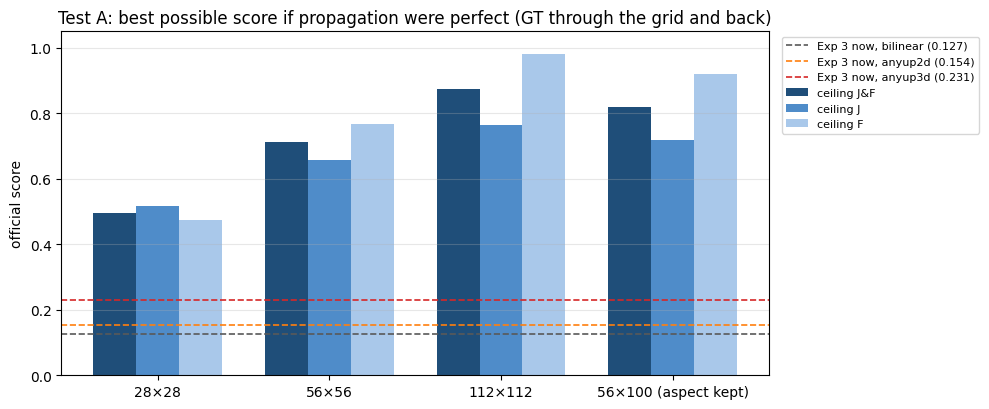

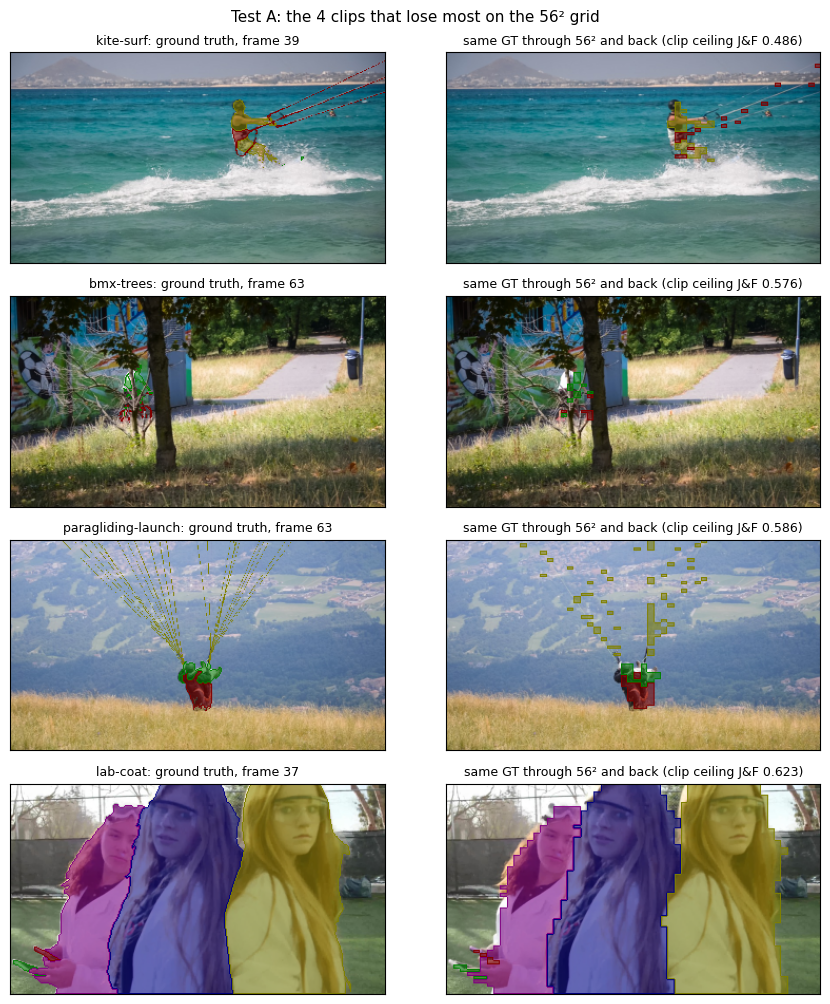

In [4]:
# ── Cell 4 · Test A · resolution ceiling (no model) ────────────────────────
# GT masks of every frame → nearest to the grid → nearest back to native → official J&F. This is the score a PERFECT
# propagation would get on that grid, so it is an upper bound for Exp 3 at PROP_SIZE. Also counts frame-0 objects
# that (almost) vanish on the PROP_SIZE² grid: those can never be propagated.
if RUN_A:
    t_start = time.perf_counter()
    CEIL = {g: {} for g in GRIDS_A}
    lost = []
    for ci, clip in enumerate(CLIPS):
        gt = davis.load_annotations(ROOT, clip)                                     # (T, 480, W) uint8
        H0, W0 = gt.shape[1:]
        for g in GRIDS_A:
            rt = np.stack([davis.resize_labels(davis.resize_labels(m, g), (H0, W0)) for m in gt])   # (T, 480, W)
            rt[rt == 255] = 0                                                       # void → bg (a prediction has no void)
            CEIL[g][clip] = metrics.eval_clip_jf(gt, rt)
        a0 = davis.resize_labels(gt[0], (PROP_SIZE, PROP_SIZE))
        for k in range(1, int(gt[0][gt[0] != 255].max()) + 1):
            n_nat, n_lr = int((gt[0] == k).sum()), int((a0 == k).sum())
            if n_lr <= 2:
                lost.append((clip, k, n_nat, n_lr))
        print(f"[{ci + 1}/{len(CLIPS)}] {clip:<18} " +
              "  ".join(f"{g[0]}×{g[1]}: {clip_mean_jf(CEIL[g][clip]):.3f}" for g in GRIDS_A))
    CEIL_SUM = {g: metrics.summarize_jf(CEIL[g]) for g in GRIDS_A}
    print(f"\nTest A done in {time.perf_counter() - t_start:.0f}s. Ceiling = J&F of the GT itself after the grid round trip:")
    for g in GRIDS_A:
        s = CEIL_SUM[g]
        print(f"  grid {g[0]:>3}×{g[1]:<3}  J&F {s['J&F-Mean']:.4f}  J {s['J-Mean']:.4f}  F {s['F-Mean']:.4f}")
    print(f"  Exp 3 now (T05, 56×56): " + ", ".join(f"{c} {v:.4f}" for c, v in T05_REF.items()))
    print(f"\nframe-0 objects with ≤ 2 pixels on the {PROP_SIZE}² grid (cannot be propagated): {len(lost)}")
    for clip, k, n_nat, n_lr in lost:
        print(f"  {clip} object {k}: {n_nat} px native → {n_lr} px")

    # figure 1: ceiling per grid vs what Exp 3 reaches now
    fig, ax = plt.subplots(figsize=(10, 4.2))
    labels = [f"{g[0]}×{g[1]}" + (" (aspect kept)" if g[0] != g[1] else "") for g in GRIDS_A]
    x = np.arange(len(GRIDS_A))
    for k, (key, lab) in enumerate([("J&F-Mean", "J&F"), ("J-Mean", "J"), ("F-Mean", "F")]):
        ax.bar(x + (k - 1) * 0.25, [CEIL_SUM[g][key] for g in GRIDS_A], 0.25, label=f"ceiling {lab}",
               color=["#1f4e79", "#4f8cc9", "#a9c8ea"][k])
    for c, v in T05_REF.items():
        ax.axhline(v, ls="--", lw=1.2, color={"bilinear": "0.35", "anyup2d": "tab:orange", "anyup3d": "tab:red"}[c],
                   label=f"Exp 3 now, {c} ({v:.3f})")
    ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0, 1.05); ax.set_ylabel("official score")
    ax.set_title("Test A: best possible score if propagation were perfect (GT through the grid and back)")
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); ax.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.savefig(OUT_DIR / "A_ceiling.png", dpi=130, bbox_inches="tight"); plt.show()

    # figure 2: the clips that lose most on the PROP_SIZE² grid: GT vs GT after the round trip
    g56 = (PROP_SIZE, PROP_SIZE)
    worst = sorted(CEIL[g56], key=lambda c: clip_mean_jf(CEIL[g56][c]))[:N_SHOW]
    fig, axes = plt.subplots(len(worst), 2, figsize=(9, 2.4 * len(worst) + 0.6), squeeze=False)
    for r, clip in enumerate(worst):
        T = len(davis.frame_paths(ROOT, clip))
        t = min(T - 1, int(round(SHOW_FRAC * (T - 1))))
        img, gt_s, hw = frame_and_gt(clip, t)
        gt_nat = davis.load_annotation(davis.ann_paths(ROOT, clip)[t])
        rt = davis.resize_labels(davis.resize_labels(gt_nat, g56), hw)
        axes[r, 0].imshow(viz.overlay(img, gt_s)); axes[r, 0].set_title(f"{clip}: ground truth, frame {t}", fontsize=9)
        axes[r, 1].imshow(viz.overlay(img, rt))
        axes[r, 1].set_title(f"same GT through {PROP_SIZE}² and back (clip ceiling J&F {clip_mean_jf(CEIL[g56][clip]):.3f})", fontsize=9)
        for ax in axes[r]:
            ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"Test A: the {len(worst)} clips that lose most on the {PROP_SIZE}² grid", fontsize=11)
    plt.tight_layout(); plt.savefig(OUT_DIR / "A_worst_clips.png", dpi=130, bbox_inches="tight"); plt.show()
else:
    print("RUN_A=False — skipped")

Downloading: "https://download.pytorch.org/models/swin3d_t-7615ae03.pth" to /root/.cache/torch/hub/checkpoints/swin3d_t-7615ae03.pth


100%|██████████| 122M/122M [00:00<00:00, 199MB/s]


check (i) propagate_local(radius=None) vs davis.propagate_labels on bike-packing: 0 differing pixels → PASS
[1/30] bike-packing       swin224/bilinear 0.102  swin224+w6/bilinear 0.144  swin224+w12/bilinear 0.107  swin224/anyup3d 0.339  swin224+w6/anyup3d 0.327  swin224+w12/anyup3d 0.312  40s
[2/30] blackswan          swin224/bilinear 0.322  swin224+w6/bilinear 0.322  swin224+w12/bilinear 0.322  swin224/anyup3d 0.496  swin224+w6/anyup3d 0.497  swin224+w12/anyup3d 0.496  23s
[3/30] bmx-trees          swin224/bilinear 0.055  swin224+w6/bilinear 0.047  swin224+w12/bilinear 0.055  swin224/anyup3d 0.055  swin224+w6/anyup3d 0.056  swin224+w12/anyup3d 0.055  43s
[4/30] breakdance         swin224/bilinear 0.059  swin224+w6/bilinear 0.061  swin224+w12/bilinear 0.061  swin224/anyup3d 0.272  swin224+w6/anyup3d 0.301  swin224+w12/anyup3d 0.275  39s
[5/30] camel              swin224/bilinear 0.293  swin224+w6/bilinear 0.295  swin224+w12/bilinear 0.293  swin224/anyup3d 0.450  swin224+w6/anyup3d 0.446

/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union


[17/30] india              swin224/bilinear 0.256  swin224+w6/bilinear 0.213  swin224+w12/bilinear 0.256  swin224/anyup3d 0.354  swin224+w6/anyup3d 0.371  swin224+w12/anyup3d 0.349  51s
[18/30] judo               swin224/bilinear 0.232  swin224+w6/bilinear 0.243  swin224+w12/bilinear 0.232  swin224/anyup3d 0.244  swin224+w6/anyup3d 0.226  swin224+w12/anyup3d 0.244  18s


/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union


[19/30] kite-surf          swin224/bilinear 0.101  swin224+w6/bilinear 0.101  swin224+w12/bilinear 0.101  swin224/anyup3d 0.217  swin224+w6/anyup3d 0.217  swin224+w12/anyup3d 0.217  30s
[20/30] lab-coat           swin224/bilinear 0.076  swin224+w6/bilinear 0.077  swin224+w12/bilinear 0.076  swin224/anyup3d 0.117  swin224+w6/anyup3d 0.116  swin224+w12/anyup3d 0.117  36s
[21/30] libby              swin224/bilinear 0.054  swin224+w6/bilinear 0.078  swin224+w12/bilinear 0.059  swin224/anyup3d 0.250  swin224+w6/anyup3d 0.254  swin224+w12/anyup3d 0.250  22s
[22/30] loading            swin224/bilinear 0.225  swin224+w6/bilinear 0.216  swin224+w12/bilinear 0.210  swin224/anyup3d 0.250  swin224+w6/anyup3d 0.246  swin224+w12/anyup3d 0.247  30s
[23/30] mbike-trick        swin224/bilinear 0.030  swin224+w6/bilinear 0.031  swin224+w12/bilinear 0.030  swin224/anyup3d 0.011  swin224+w6/anyup3d 0.011  swin224+w12/anyup3d 0.011  43s
[24/30] motocross-jump     swin224/bilinear 0.111  swin224+w6/bilinear

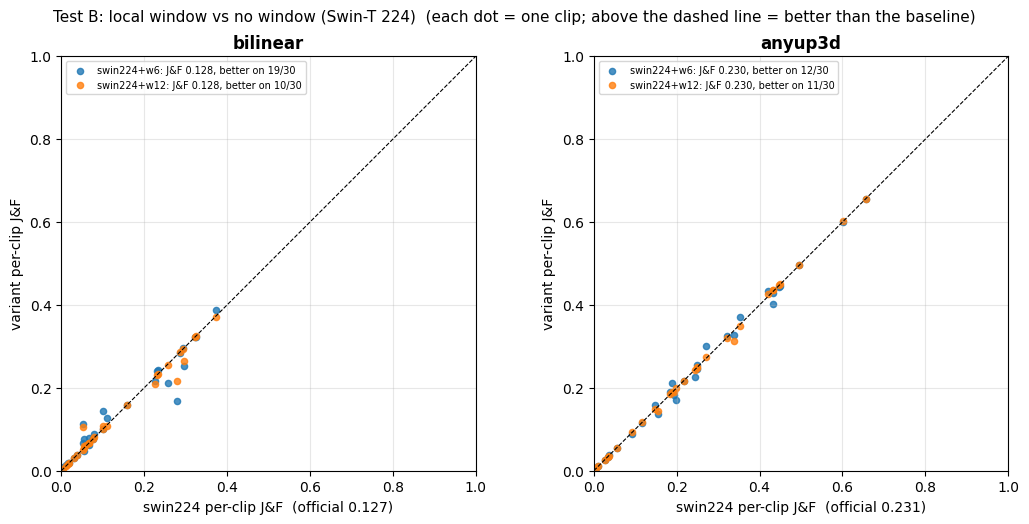

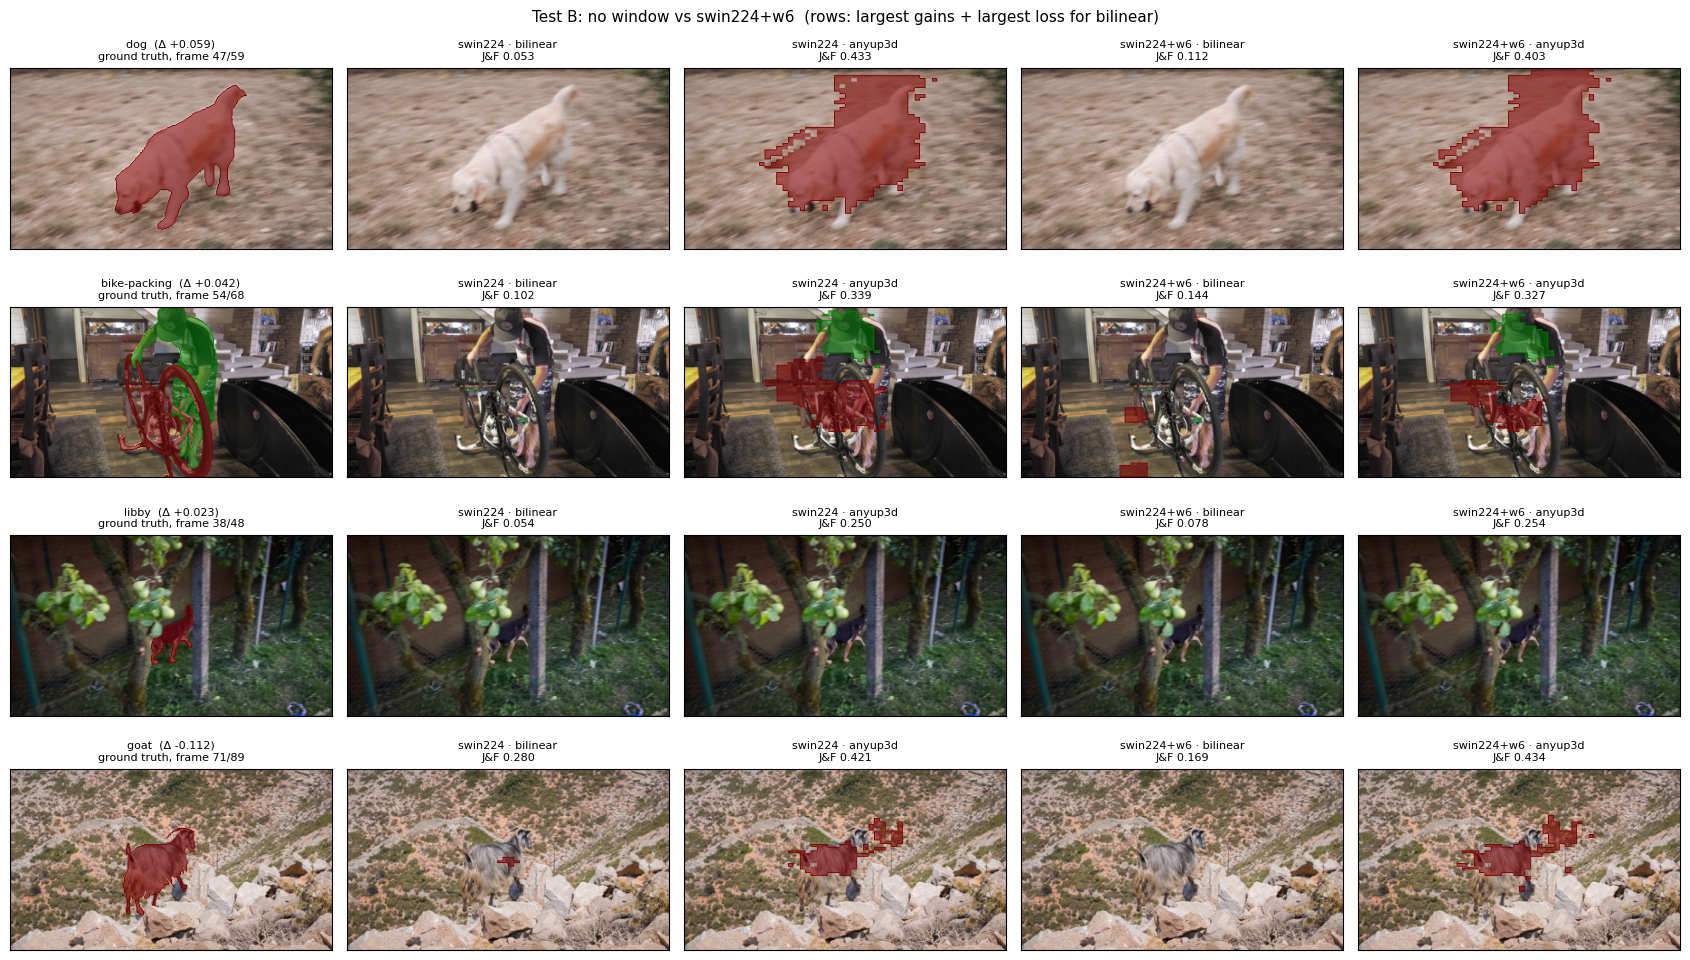

In [5]:
# ── Cell 5 · Baseline (= Exp 3) + Test B · local window ────────────────────
# Swin-T 224 (7×7 grid) as in Exp 3. The same upsampled features are propagated without a window (= Exp 3) and with
# square windows of RADII grid cells, so only the matching rule changes.
if RUN_B:
    bb = BackboneLoader.load("swin_t", device=DEVICE, guide_size=PROP_SIZE, temporal_mode="per_frame", norm=SWIN_NORM)

    # check (i): the notebook's propagation without a window = davis.propagate_labels (first clip, first condition)
    gt0 = davis.load_annotations(ROOT, CLIPS[0])
    ch0 = list(iter_backbone_chunks(bb, davis.open_clip(ROOT, CLIPS[0]), chunk_size=CHUNK_SIZE, overlap=0))
    f0 = torch.cat([UPS[CONDITIONS[0]](ch, output_size=PROP_SIZE).features for ch in ch0])   # (T, 768, P, P)
    n_diff = int((propagate_local(f0, gt0[0]) != davis.propagate_labels(f0, gt0[0], tau=TAU, top_k=TOP_K, n_last=N_LAST)).sum())
    print(f"check (i) propagate_local(radius=None) vs davis.propagate_labels on {CLIPS[0]}: {n_diff} differing pixels "
          f"→ {'PASS' if n_diff == 0 else 'FAIL'}")
    del ch0, f0
    torch.cuda.empty_cache()

    lr_panel(bb, "swin_t 224")
    B_NAMES = run_backbone(bb, "swin224", CHUNK_SIZE, [None] + list(RADII))
    del bb
    torch.cuda.empty_cache()

    if "swin224" not in RES:
        raise RuntimeError(f"baseline skipped ({SKIPPED.get('swin224')}); reduce CHUNK_SIZE and re-run this cell")

    # check (ii): the baseline reproduces the T05 Exp 3 numbers (only meaningful with all 30 clips)
    for c in CONDITIONS:
        v = official("swin224", c)["J&F-Mean"]
        if len(CLIPS) == 30 and c in T05_REF:
            ok = abs(v - T05_REF[c]) < 0.002
            print(f"check (ii) baseline {c}: J&F {v:.4f} vs T05 {T05_REF[c]:.4f} → {'PASS' if ok else 'WARN (|diff| ≥ 0.002)'}")
        else:
            print(f"check (ii) baseline {c}: J&F {v:.4f} (not compared: needs all 30 clips)")

    print()
    print_table(B_NAMES, base="swin224")
    if len(B_NAMES) > 1:
        best_b = max(B_NAMES[1:], key=lambda v: official(v, CONDITIONS[0])["J&F-Mean"])
        scatter_figure("swin224", B_NAMES[1:], "Test B: local window vs no window (Swin-T 224)", OUT_DIR / "B_scatter.png")
        sel, d = pick_clips("swin224", best_b, CONDITIONS[0])
        mask_figure(["swin224", best_b], sel, d,
                    f"Test B: no window vs {best_b}  (rows: largest gains + largest loss for {CONDITIONS[0]})", OUT_DIR / "B_masks.png")
else:
    print("RUN_B=False — skipped (Tests C and D need this baseline)")

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

[1/30] bike-packing       dino224/bilinear 0.409  dino224+w12/bilinear 0.406  dino224/anyup3d 0.474  dino224+w12/anyup3d 0.473  30s
[2/30] blackswan          dino224/bilinear 0.581  dino224+w12/bilinear 0.581  dino224/anyup3d 0.758  dino224+w12/anyup3d 0.758  17s
[3/30] bmx-trees          dino224/bilinear 0.251  dino224+w12/bilinear 0.251  dino224/anyup3d 0.185  dino224+w12/anyup3d 0.185  32s
[4/30] breakdance         dino224/bilinear 0.524  dino224+w12/bilinear 0.524  dino224/anyup3d 0.599  dino224+w12/anyup3d 0.599  30s
[5/30] camel              dino224/bilinear 0.413  dino224+w12/bilinear 0.413  dino224/anyup3d 0.542  dino224+w12/anyup3d 0.542  32s
[6/30] car-roundabout     dino224/bilinear 0.694  dino224+w12/bilinear 0.689  dino224/anyup3d 0.759  dino224+w12/anyup3d 0.759  26s
[7/30] car-shadow         dino224/bilinear 0.626  dino224+w12/bilinear 0.625  dino224/anyup3d 0.701  dino224+w12/anyup3d 0.701  13s
[8/30] cows               dino224/bilinear 0.488  dino224+w12/bilinear 0.488

/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union


[17/30] india              dino224/bilinear 0.451  dino224+w12/bilinear 0.451  dino224/anyup3d 0.473  dino224+w12/anyup3d 0.473  38s
[18/30] judo               dino224/bilinear 0.482  dino224+w12/bilinear 0.482  dino224/anyup3d 0.467  dino224+w12/anyup3d 0.467  13s


/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union


[19/30] kite-surf          dino224/bilinear 0.189  dino224+w12/bilinear 0.189  dino224/anyup3d 0.277  dino224+w12/anyup3d 0.277  23s
[20/30] lab-coat           dino224/bilinear 0.206  dino224+w12/bilinear 0.206  dino224/anyup3d 0.214  dino224+w12/anyup3d 0.214  27s
[21/30] libby              dino224/bilinear 0.422  dino224+w12/bilinear 0.422  dino224/anyup3d 0.499  dino224+w12/anyup3d 0.499  17s
[22/30] loading            dino224/bilinear 0.474  dino224+w12/bilinear 0.464  dino224/anyup3d 0.486  dino224+w12/anyup3d 0.486  23s
[23/30] mbike-trick        dino224/bilinear 0.387  dino224+w12/bilinear 0.387  dino224/anyup3d 0.393  dino224+w12/anyup3d 0.394  33s
[24/30] motocross-jump     dino224/bilinear 0.232  dino224+w12/bilinear 0.226  dino224/anyup3d 0.278  dino224+w12/anyup3d 0.278  15s
[25/30] paragliding-launch dino224/bilinear 0.145  dino224+w12/bilinear 0.145  dino224/anyup3d 0.231  dino224+w12/anyup3d 0.231  37s
[26/30] parkour            dino224/bilinear 0.328  dino224+w12/biline

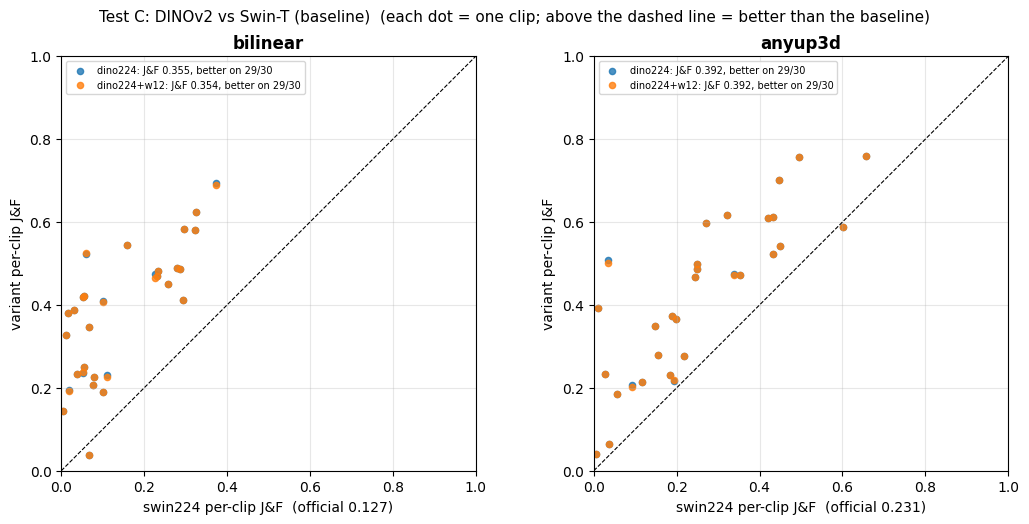

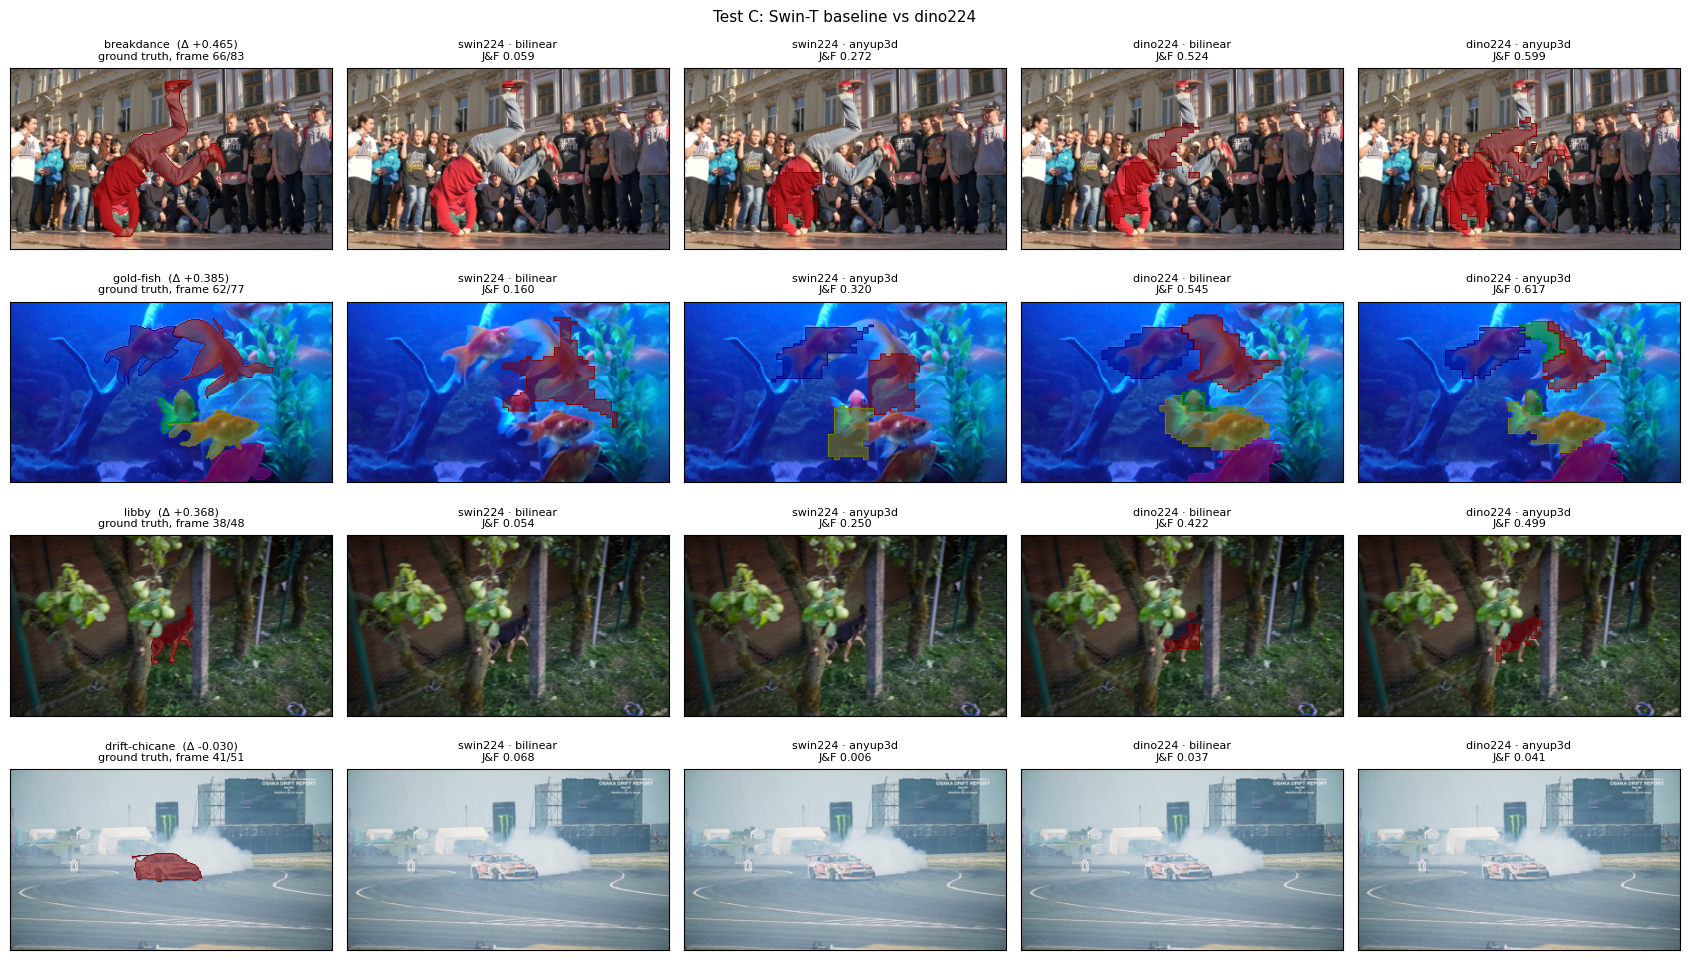

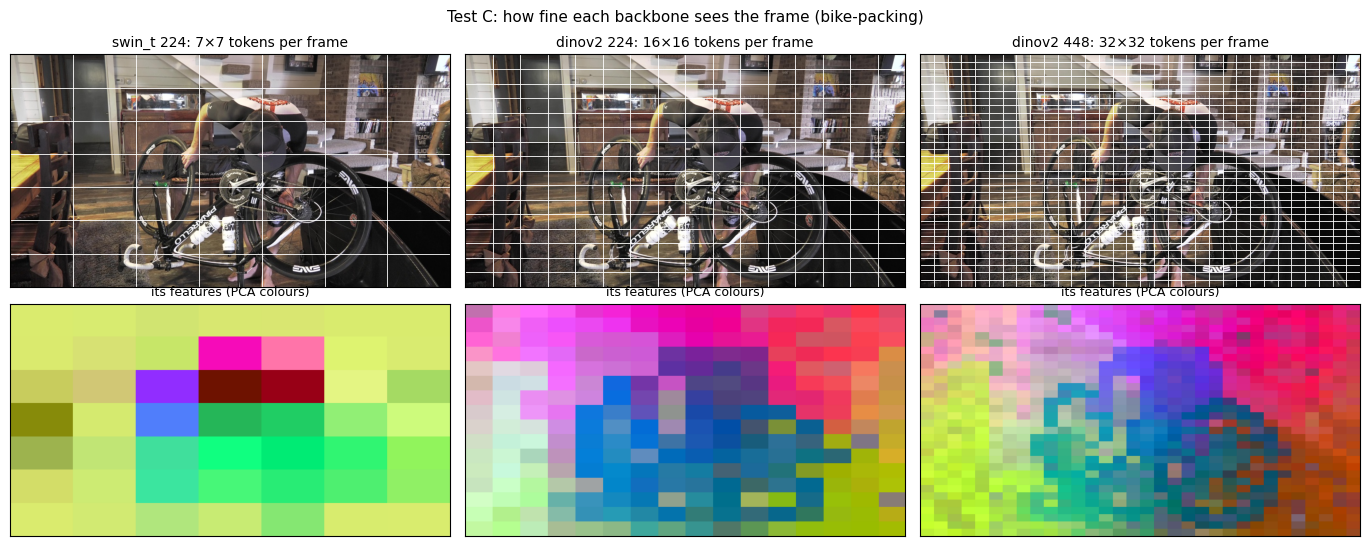

In [6]:
# ── Cell 6 · Test C · DINOv2-base per frame instead of Swin-T ──────────────
# Same propagation, upsamplers, sizes and scoring; only the backbone changes (DINOv2 is self-supervised, made for
# dense features; Swin-T is a supervised action classifier). Without and with the window (WINDOW_CD).
if RUN_C:
    assert "swin224" in RES, "Test C compares against the baseline: run Cell 5 first (RUN_B=True)"
    C_NAMES = []
    for size in DINO_INPUTS:
        bb = BackboneLoader.load("dinov2", device=DEVICE, input_size=size, guide_size=PROP_SIZE, variant="base")
        lr_panel(bb, f"dinov2 {size}")
        C_NAMES += run_backbone(bb, f"dino{size}", CHUNK_SIZE_C, [None] + ([WINDOW_CD] if WINDOW_CD else []))
        del bb
        torch.cuda.empty_cache()
    if C_NAMES:
        print()
        print_table(["swin224"] + C_NAMES, base="swin224")
        scatter_figure("swin224", C_NAMES, "Test C: DINOv2 vs Swin-T (baseline)", OUT_DIR / "C_scatter.png")
        best_c = max(C_NAMES, key=lambda v: official(v, CONDITIONS[0])["J&F-Mean"])
        sel, d = pick_clips("swin224", best_c, CONDITIONS[0])
        mask_figure(["swin224", best_c], sel, d, f"Test C: Swin-T baseline vs {best_c}", OUT_DIR / "C_masks.png")
    grid_figure(["swin_t 224"] + [f"dinov2 {s}" for s in DINO_INPUTS],
                f"Test C: how fine each backbone sees the frame ({SHOW_CLIP})", OUT_DIR / "C_grids.png")
else:
    print("RUN_C=False — skipped")

[1/30] bike-packing       swin448/bilinear 0.288  swin448+w12/bilinear 0.284  swin448/anyup3d 0.387  swin448+w12/anyup3d 0.387  28s
[2/30] blackswan          swin448/bilinear 0.352  swin448+w12/bilinear 0.352  swin448/anyup3d 0.637  swin448+w12/anyup3d 0.637  17s
[3/30] bmx-trees          swin448/bilinear 0.119  swin448+w12/bilinear 0.072  swin448/anyup3d 0.079  swin448+w12/anyup3d 0.078  32s
[4/30] breakdance         swin448/bilinear 0.111  swin448+w12/bilinear 0.111  swin448/anyup3d 0.373  swin448+w12/anyup3d 0.380  28s
[5/30] camel              swin448/bilinear 0.320  swin448+w12/bilinear 0.318  swin448/anyup3d 0.472  swin448+w12/anyup3d 0.472  30s
[6/30] car-roundabout     swin448/bilinear 0.357  swin448+w12/bilinear 0.354  swin448/anyup3d 0.652  swin448+w12/anyup3d 0.643  25s
[7/30] car-shadow         swin448/bilinear 0.444  swin448+w12/bilinear 0.448  swin448/anyup3d 0.552  swin448+w12/anyup3d 0.570  13s
[8/30] cows               swin448/bilinear 0.424  swin448+w12/bilinear 0.424

/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union


[17/30] india              swin448/bilinear 0.347  swin448+w12/bilinear 0.346  swin448/anyup3d 0.436  swin448+w12/anyup3d 0.435  37s
[18/30] judo               swin448/bilinear 0.328  swin448+w12/bilinear 0.328  swin448/anyup3d 0.454  swin448+w12/anyup3d 0.447  13s


/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union
/content/anyup/anyup/metrics.py:94: RuntimeWarning: invalid value encountered in divide
  j = inters / union


[19/30] kite-surf          swin448/bilinear 0.104  swin448+w12/bilinear 0.104  swin448/anyup3d 0.137  swin448+w12/anyup3d 0.137  22s
[20/30] lab-coat           swin448/bilinear 0.123  swin448+w12/bilinear 0.124  swin448/anyup3d 0.164  swin448+w12/anyup3d 0.165  26s
[21/30] libby              swin448/bilinear 0.238  swin448+w12/bilinear 0.234  swin448/anyup3d 0.374  swin448+w12/anyup3d 0.373  16s
[22/30] loading            swin448/bilinear 0.278  swin448+w12/bilinear 0.282  swin448/anyup3d 0.424  swin448+w12/anyup3d 0.420  22s
[23/30] mbike-trick        swin448/bilinear 0.209  swin448+w12/bilinear 0.209  swin448/anyup3d 0.297  swin448+w12/anyup3d 0.297  31s
[24/30] motocross-jump     swin448/bilinear 0.037  swin448+w12/bilinear 0.037  swin448/anyup3d 0.201  swin448+w12/anyup3d 0.201  15s
[25/30] paragliding-launch swin448/bilinear 0.030  swin448+w12/bilinear 0.030  swin448/anyup3d 0.223  swin448+w12/anyup3d 0.223  36s
[26/30] parkour            swin448/bilinear 0.066  swin448+w12/biline

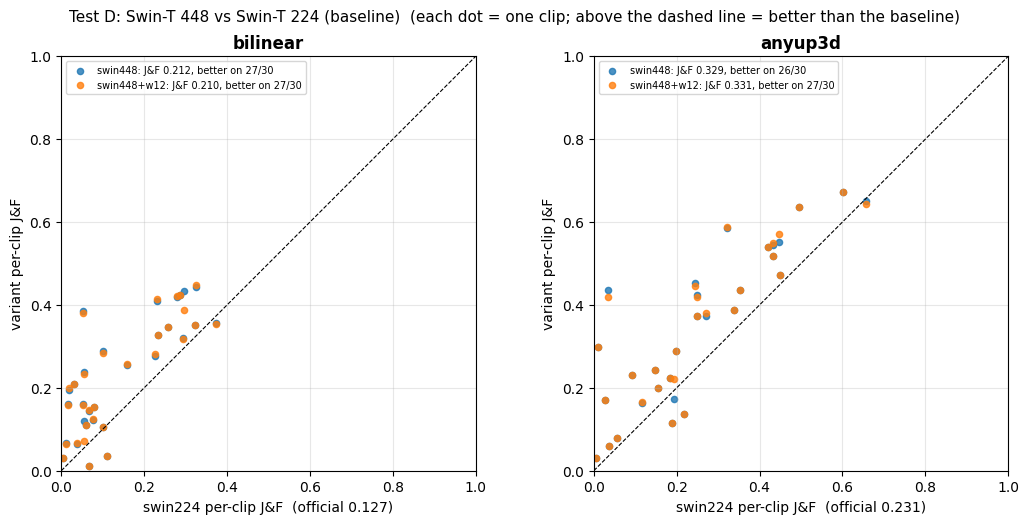

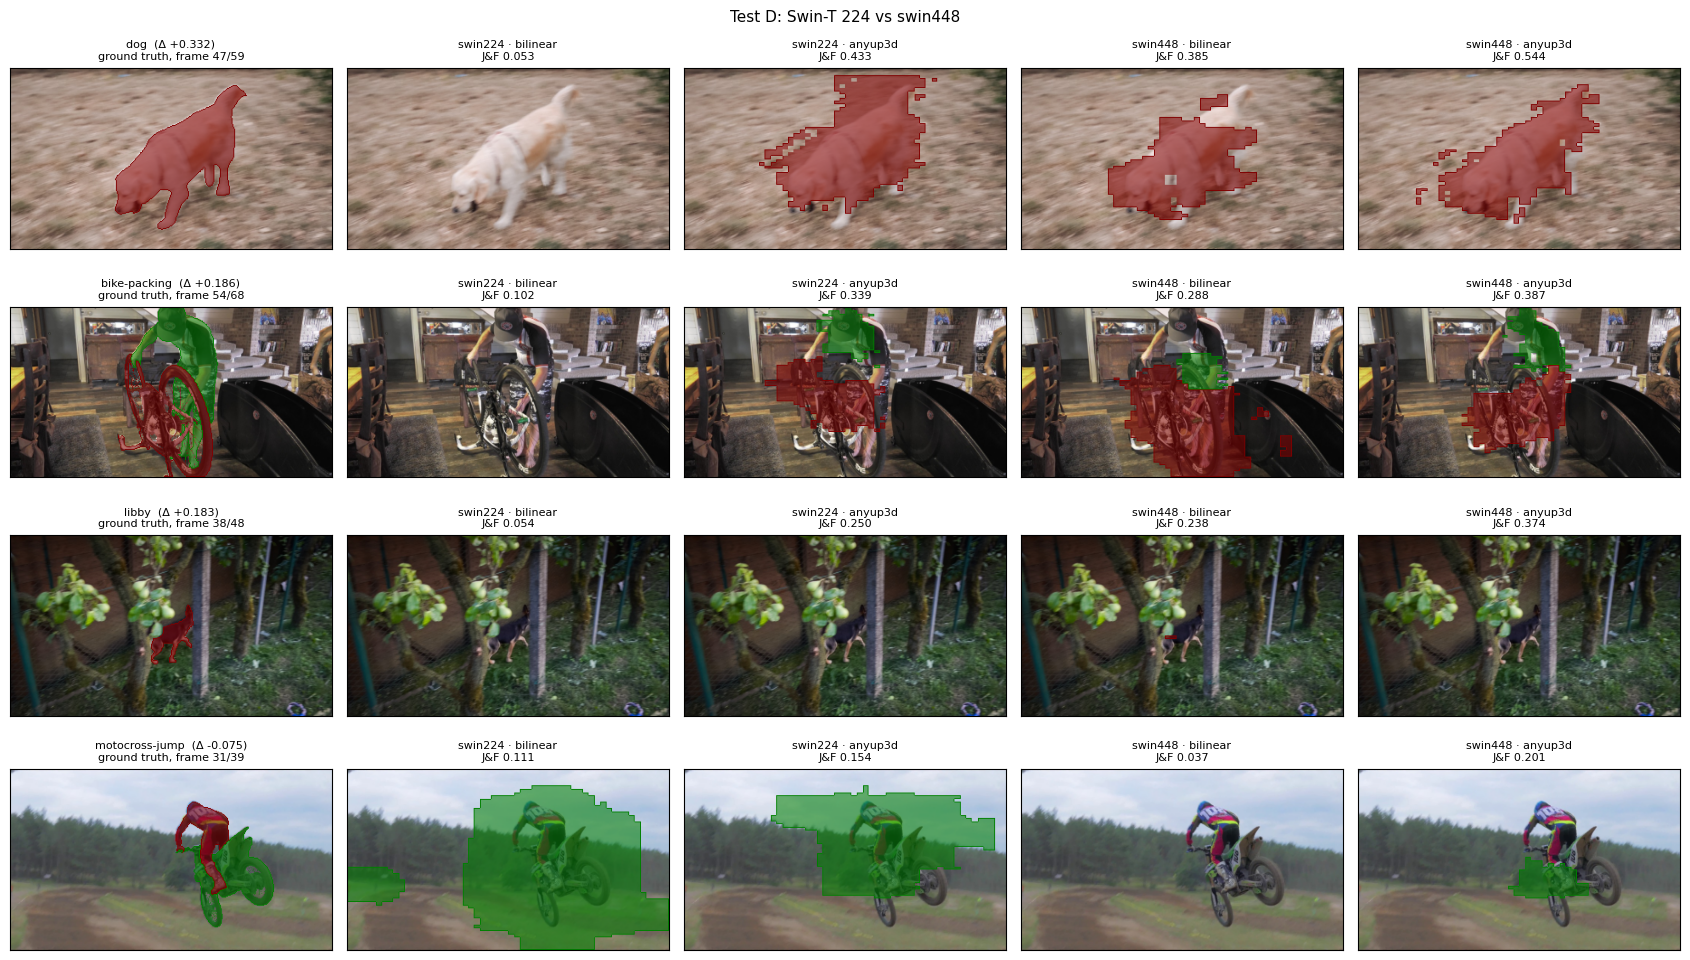

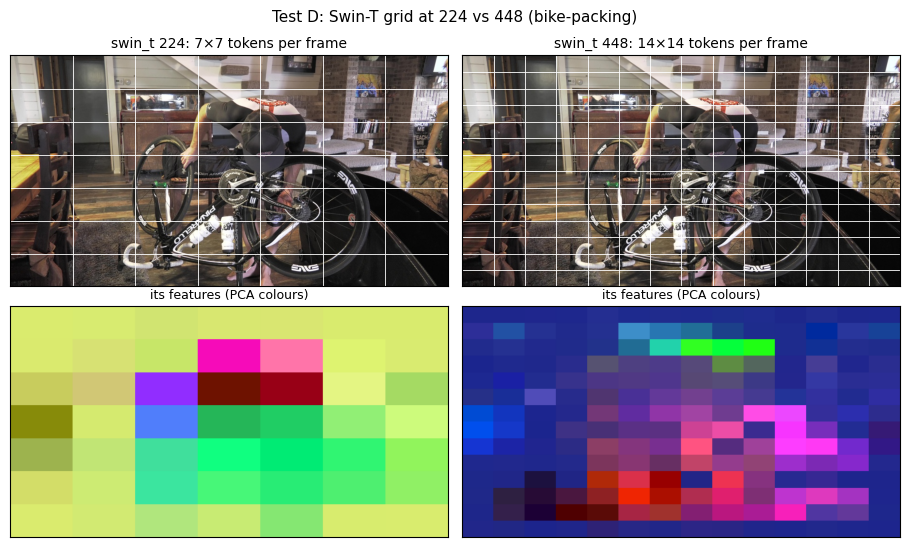

In [7]:
# ── Cell 7 · Test D · Swin-T at a larger input (finer grid) ────────────────
# Same backbone as Exp 3, input SWIN_INPUT_D instead of 224 → a 2× finer grid (14×14 at 448). Isolates the grid size
# from the backbone type (compare with Test C).
if RUN_D:
    assert "swin224" in RES, "Test D compares against the baseline: run Cell 5 first (RUN_B=True)"
    bb = BackboneLoader.load("swin_t", device=DEVICE, input_size=SWIN_INPUT_D, guide_size=PROP_SIZE,
                             temporal_mode="per_frame", norm=SWIN_NORM)
    lr_panel(bb, f"swin_t {SWIN_INPUT_D}")
    D_NAMES = run_backbone(bb, f"swin{SWIN_INPUT_D}", CHUNK_SIZE_D, [None] + ([WINDOW_CD] if WINDOW_CD else []))
    del bb
    torch.cuda.empty_cache()
    if D_NAMES:
        print()
        print_table(["swin224"] + D_NAMES, base="swin224")
        scatter_figure("swin224", D_NAMES, f"Test D: Swin-T {SWIN_INPUT_D} vs Swin-T 224 (baseline)", OUT_DIR / "D_scatter.png")
        best_d = max(D_NAMES, key=lambda v: official(v, CONDITIONS[0])["J&F-Mean"])
        sel, d = pick_clips("swin224", best_d, CONDITIONS[0])
        mask_figure(["swin224", best_d], sel, d, f"Test D: Swin-T 224 vs {best_d}", OUT_DIR / "D_masks.png")
    grid_figure(["swin_t 224", f"swin_t {SWIN_INPUT_D}"], f"Test D: Swin-T grid at 224 vs {SWIN_INPUT_D} ({SHOW_CLIP})",
                OUT_DIR / "D_grids.png")
else:
    print("RUN_D=False — skipped")

variant          cond           grid     J&F       J       F   Δ J&F vs base   better/clips
swin224          bilinear     (7, 7)  0.1272  0.1580  0.0965
swin224          anyup3d      (7, 7)  0.2309  0.2424  0.2194
swin224+w6       bilinear     (7, 7)  0.1277  0.1573  0.0981   +0.0004        19/30
swin224+w6       anyup3d      (7, 7)  0.2298  0.2394  0.2203   -0.0010        12/30
swin224+w12      bilinear     (7, 7)  0.1275  0.1593  0.0957   +0.0003        10/30
swin224+w12      anyup3d      (7, 7)  0.2295  0.2411  0.2180   -0.0014        11/30
dino224          bilinear   (16, 16)  0.3550  0.4019  0.3081   +0.2278        29/30
dino224          anyup3d    (16, 16)  0.3922  0.4061  0.3782   +0.1613        29/30
dino224+w12      bilinear   (16, 16)  0.3541  0.4009  0.3074   +0.2269        29/30
dino224+w12      anyup3d    (16, 16)  0.3919  0.4057  0.3781   +0.1610        29/30
swin448          bilinear   (14, 14)  0.2117  0.2591  0.1643   +0.0845        27/30
swin448          anyup3d    (1

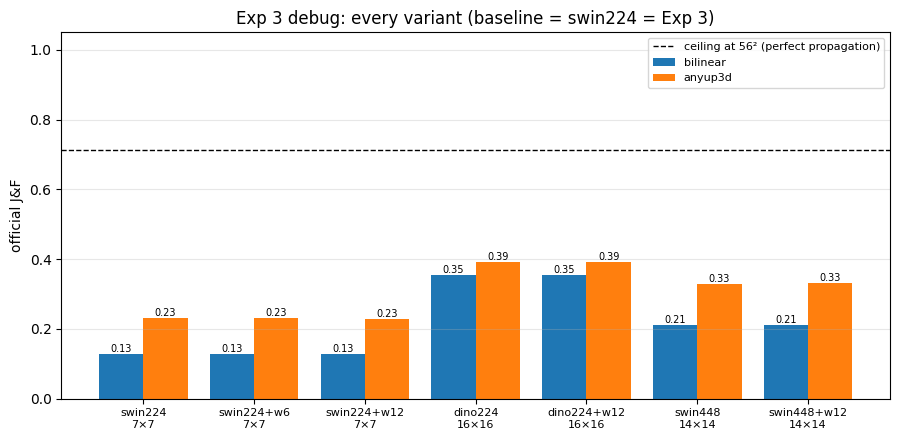


saved: /content/drive/MyDrive/results/T11/exp3_debug/p56_n30_bilinear-anyup3d/exp3_debug_per_item.csv /content/drive/MyDrive/results/T11/exp3_debug/p56_n30_bilinear-anyup3d/exp3_debug_summary.json + figures in /content/drive/MyDrive/results/T11/exp3_debug/p56_n30_bilinear-anyup3d


In [8]:
# ── Cell 8 · Summary + save ────────────────────────────────────────────────
variants = list(RES)
base = "swin224" if "swin224" in RES else None
if variants:
    print_table(variants, base=base)
if "CEIL_SUM" in globals():
    print("\nTest A ceilings (perfect propagation): " +
          ", ".join(f"{g[0]}×{g[1]} {CEIL_SUM[g]['J&F-Mean']:.3f}" for g in GRIDS_A))
for k, why in SKIPPED.items():
    print(f"SKIPPED {k}: {why}")

rows, summary = [], {"variants": {}, "paired_vs_baseline": {}, "skipped": SKIPPED, "grids": GRIDS}
for v in variants:
    for c in CONDITIONS:
        s = official(v, c)
        summary["variants"][f"{v}/{c}"] = {k: s[k] for k in ("J&F-Mean", "J-Mean", "J-Recall", "J-Decay", "F-Mean",
                                                             "F-Recall", "F-Decay", "n_clips", "n_objects")}
        for clip, pc in s["per_clip"].items():
            rows.append(dict(variant=v, condition=c, clip=clip, grid=str(GRIDS[v]), J=pc["J"], F=pc["F"], JF=pc["JF"],
                             n_objects=pc["n_objects"]))
        if base and v != base:
            a, b = per_clip(base, c), per_clip(v, c)
            summary["paired_vs_baseline"][f"{v}/{c}"] = metrics.paired_stats([b[k] for k in a], [a[k] for k in a])
if "CEIL_SUM" in globals():
    summary["ceiling"] = {f"{g[0]}x{g[1]}": {k: CEIL_SUM[g][k] for k in ("J&F-Mean", "J-Mean", "F-Mean")} for g in GRIDS_A}

if variants:
    fig, ax = plt.subplots(figsize=(max(8, 1.3 * len(variants)), 4.5))
    x = np.arange(len(variants))
    wdt = 0.8 / len(CONDITIONS)
    for k, c in enumerate(CONDITIONS):
        vals = [official(v, c)["J&F-Mean"] for v in variants]
        bars = ax.bar(x + (k - (len(CONDITIONS) - 1) / 2) * wdt, vals, wdt, label=c)
        ax.bar_label(bars, fmt="%.2f", fontsize=7)
    if "CEIL_SUM" in globals():
        ax.axhline(CEIL_SUM[(PROP_SIZE, PROP_SIZE)]["J&F-Mean"], color="k", ls="--", lw=1,
                   label=f"ceiling at {PROP_SIZE}² (perfect propagation)")
    ax.set_xticks(x); ax.set_xticklabels([f"{v}\n{GRIDS[v][0]}×{GRIDS[v][1]}" for v in variants], fontsize=8)
    ax.set_ylabel("official J&F"); ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=0.3); ax.legend(fontsize=8)
    ax.set_title("Exp 3 debug: every variant (baseline = swin224 = Exp 3)")
    plt.tight_layout(); plt.savefig(OUT_DIR / "summary.png", dpi=130, bbox_inches="tight"); plt.show()

config = dict(N_CLIPS=N_CLIPS, clips=CLIPS, CKPT_ANYUP3D=CKPT_ANYUP3D, SEED=SEED, CONDITIONS=CONDITIONS, SWIN_NORM=SWIN_NORM,
              PROP_SIZE=PROP_SIZE, TAU=TAU, TOP_K=TOP_K, N_LAST=N_LAST, CHUNK_SIZE=CHUNK_SIZE, Q_CHUNK=Q_CHUNK,
              GRIDS_A=GRIDS_A, RADII=RADII, DINO_INPUTS=DINO_INPUTS, CHUNK_SIZE_C=CHUNK_SIZE_C, SWIN_INPUT_D=SWIN_INPUT_D,
              CHUNK_SIZE_D=CHUNK_SIZE_D, WINDOW_CD=WINDOW_CD, RUN=dict(A=RUN_A, B=RUN_B, C=RUN_C, D=RUN_D),
              gpu=GPU_NAME, repo_branch=REPO_BRANCH)
csv_path, json_path = metrics.save_results(OUT_DIR, rows, summary, config, name="exp3_debug")
print("\nsaved:", csv_path, json_path, "+ figures in", OUT_DIR)

In [ ]:
# ── Cell 9 · Test E · bilinear + AnyUp2D at higher resolution + DINO reference protocol ──────────────
# Question: with a good backbone (DINOv2-B) and finer grids, does the pipeline itself give good masks with the simple
# upsamplers? E_REF runs the published DINO label-propagation protocol (no upsampler, native token grid) as an
# external check that our propagation + scoring code is right. Needs Cells 1–3 only (independent of Cells 4–8).
if RUN_E:
    t_all = time.perf_counter()
    E_UPS = {c: (UPS[c] if c in UPS else UpsamplerLoader.load(c, device=DEVICE)) for c in E_CONDITIONS}
    RES_E, PREDS_E, GRIDS_E, LOST_E, CEIL_E, SKIPPED_E = {}, {}, {}, {}, {}, {}

    def propagate_e(feats_flat, hw, ann0, tau, top_k, n_last, radius=None, q_chunk=E_Q_CHUNK):
        """
        Same rule as davis.propagate_labels, computed in query chunks (memory ∝ q_chunk, not h·w): each query pixel
        keeps its top_k context matches (optionally only within `radius` grid cells, DINO's size_mask_neighborhood),
        softmax over those top_k with temperature tau, label = weighted mean of their soft labels.
        feats_flat (T, N, C) unit vectors on GPU; hw = (h, w), h·w = N; ann0 (H0, W0) GT of frame 0.
        Returns soft labels (T, n_ch, h, w) on GPU.
        """
        T, N, C = feats_flat.shape
        h, w = hw
        n_objects = int(ann0.max())
        n_ch = n_objects + 1
        labels = torch.zeros(T, n_ch, N, device=feats_flat.device)                          # (T, n_ch, N)
        labels[0] = davis._label_maps_frame0(ann0, n_objects, h, w).to(feats_flat.device)
        if radius is not None:
            yy, xx = torch.meshgrid(torch.arange(h, device=feats_flat.device),
                                    torch.arange(w, device=feats_flat.device), indexing="ij")
            pos = torch.stack([yy.flatten(), xx.flatten()], 1)                               # (N, 2) grid position
        for t in range(1, T):
            ctx = [0] + list(range(max(1, t - n_last), t))                                   # frame 0 always first
            k_feats = feats_flat[ctx].reshape(-1, C)                                         # (Nctx·N, C), frame-major
            k_labels = labels[ctx].permute(1, 0, 2).reshape(n_ch, -1)                        # (n_ch, Nctx·N)
            for q0 in range(0, N, q_chunk):
                q1 = min(N, q0 + q_chunk)
                A = feats_flat[t, q0:q1] @ k_feats.T / tau                                   # (Q, Nctx·N)
                if radius is not None:
                    near = (pos[q0:q1, None, :] - pos[None, :, :]).abs().amax(-1) <= radius  # (Q, N) square window
                    A = A.masked_fill(~near.repeat(1, len(ctx)), float("-inf"))
                vals, idx = A.topk(top_k, dim=-1)                                            # (Q, top_k)
                wts = F.softmax(vals, dim=-1)                                                # (Q, top_k)
                labels[t, :, q0:q1] = (k_labels[:, idx] * wts[None]).sum(-1)                 # (n_ch, Q, top_k) → (n_ch, Q)
                del A
        return labels.view(T, n_ch, h, w)

    def clip_feats(bb, clip, cond, out_hw):
        """DINOv2 on every frame (E_CHUNK frames per call) → upsampled to out_hw by `cond` (None = native token grid)
        → L2-normalized, written chunk by chunk into one (T, N, C) GPU tensor (no second full-size copy)."""
        flat, t0 = None, 0
        for ch in iter_backbone_chunks(bb, davis.open_clip(ROOT, clip), chunk_size=E_CHUNK, overlap=0):
            f = ch.features if cond is None else E_UPS[cond](ch, output_size=out_hw).features   # (t, C, h, w)
            t, C, h, w = f.shape
            if flat is None:
                T = len(davis.frame_paths(ROOT, clip))
                flat = torch.empty(T, h * w, C, device=f.device)                             # (T, N, C)
            flat[t0:t0 + t] = F.normalize(f.reshape(t, C, h * w).permute(0, 2, 1), dim=-1)  # (t, N, C) unit vectors
            t0 += t
            del f
        assert t0 == flat.shape[0], "frame mismatch"
        return flat, (h, w)

    def score_e(pred_nat, gt):
        """Official J&F of one clip + vanished objects: (frame, object) pairs scored by the toolkit (frames 1..T-2)
        where the object is in the GT but has 0 predicted pixels."""
        lost = present = 0
        for t in range(1, len(gt) - 1):
            for k in range(1, int(gt[0][gt[0] != 255].max()) + 1):
                if (gt[t] == k).any():
                    present += 1
                    lost += int(not (pred_nat[t] == k).any())
        return metrics.eval_clip_jf(gt, pred_nat), lost, present

    def to_native(pred_lr, gt):
        return np.stack([davis.resize_labels(np.asarray(p, np.uint8), gt.shape[1:]) for p in pred_lr])   # (T, H0, W0)

    def run_e(name, input_hw, prop_hw, conds, ref=False):
        """One DINOv2 pass per clip → per condition: features → propagation → score. ref=True: DINO protocol."""
        bb = BackboneLoader.load("dinov2", device=DEVICE, input_size=input_hw,
                                 guide_size=prop_hw if prop_hw else input_hw, variant="base")
        for c in conds:
            RES_E[(name, c)], PREDS_E[(name, c)], LOST_E[(name, c)] = {}, {}, [0, 0]
        t_start = time.perf_counter()
        try:
            for ci, clip in enumerate(CLIPS):
                t0 = time.perf_counter()
                gt = davis.load_annotations(ROOT, clip)                                     # (T, 480, W) uint8
                line = []
                for c in conds:   # backbone re-run per condition: holding two full-size feature sets would double GPU memory
                    flat, hw = clip_feats(bb, clip, None if ref else c, prop_hw)
                    GRIDS_E[name] = hw
                    if ref:
                        soft = propagate_e(flat, hw, gt[0], E_REF["tau"], E_REF["top_k"], E_REF["n_last"], E_REF["radius"])
                        pred = torch.stack([F.interpolate(s[None], scale_factor=14, mode="bilinear", align_corners=False)[0].argmax(0)
                                            for s in soft]).cpu().numpy()                   # (T, 14h, 14w), as DINO
                    else:
                        soft = propagate_e(flat, hw, gt[0], TAU, TOP_K, N_LAST)
                        pred = soft.argmax(1).cpu().numpy()                                 # (T, h, w), as Exp 3
                        if ci == 0 and c == conds[0] and name == E_VARIANTS[0][0]:
                            T_, N_, C_ = flat.shape                                         # check (iii): same rule as davis
                            ref_pred = davis.propagate_labels(flat.permute(0, 2, 1).reshape(T_, C_, *hw), gt[0],
                                                              tau=TAU, top_k=TOP_K, n_last=N_LAST).numpy()
                            nd = int((ref_pred != pred).sum())
                            print(f"check (iii) propagate_e vs davis.propagate_labels on {clip}: {nd} of {pred.size} "
                                  f"grid pixels differ → {'PASS' if nd <= 1e-4 * pred.size else 'WARN'}")
                    del flat, soft
                    torch.cuda.empty_cache()
                    pred_nat = to_native(pred, gt)                                          # (T, 480, W)
                    res, lost, present = score_e(pred_nat, gt)
                    RES_E[(name, c)][clip] = res
                    PREDS_E[(name, c)][clip] = pred.astype(np.uint8)
                    LOST_E[(name, c)][0] += lost; LOST_E[(name, c)][1] += present
                    line.append(f"{c} {clip_mean_jf(res):.3f}")
                print(f"[{ci + 1}/{len(CLIPS)}] {clip:<18} {name}: " + "  ".join(line) + f"  {time.perf_counter() - t0:.0f}s")
        except torch.cuda.OutOfMemoryError as e:
            for c in conds:
                RES_E.pop((name, c), None); PREDS_E.pop((name, c), None); LOST_E.pop((name, c), None)
            SKIPPED_E[name] = f"CUDA out of memory on {GPU_NAME} ({str(e).splitlines()[0][:120]}); reduce E_CHUNK / E_Q_CHUNK"
            print(f"SKIPPED {name}: {SKIPPED_E[name]}")
        del bb
        torch.cuda.empty_cache()
        print(f"{name}: grid {GRIDS_E.get(name)}, {time.perf_counter() - t_start:.0f}s")

    for name, input_hw, prop_hw in E_VARIANTS:
        run_e(name, input_hw, prop_hw, E_CONDITIONS)
    run_e("dino_ref", E_REF["input"], None, ["none"], ref=True)

    # ceiling of each E grid (Test A rule: GT → grid → native, nearest)
    if E_CEILING:
        for name, hw in GRIDS_E.items():
            ce = {}
            for clip in CLIPS:
                gt = davis.load_annotations(ROOT, clip)
                rt = np.stack([davis.resize_labels(davis.resize_labels(m, hw), gt.shape[1:]) for m in gt])
                rt[rt == 255] = 0
                ce[clip] = metrics.eval_clip_jf(gt, rt)
            CEIL_E[name] = metrics.summarize_jf(ce)["J&F-Mean"]

    SUM_E = {k: metrics.summarize_jf(v) for k, v in RES_E.items()}
    print(f"\n{'variant':<20} {'cond':<9} {'grid':>10} {'J&F':>7} {'J':>7} {'F':>7} {'ceiling':>8} {'lost obj-frames':>16}")
    for (name, c), s in SUM_E.items():
        l, p = LOST_E[(name, c)]
        print(f"{name:<20} {c:<9} {str(GRIDS_E[name]):>10} {s['J&F-Mean']:>7.4f} {s['J-Mean']:>7.4f} {s['F-Mean']:>7.4f} "
              f"{CEIL_E.get(name, float('nan')):>8.3f} {l:>7}/{p:<6} ({100 * l / max(p, 1):.1f}%)")
    print(f"(ceiling = Test A rule on that grid; dino_ref predicts at 14× its grid, so its ceiling is only approximate)")
    print(f"published reference: DINO ViT-B/16 J&F {E_REF_PAPER} (different model: an order-of-magnitude check only)")
    first = E_VARIANTS[0][0]
    if (first, "bilinear") in SUM_E:                                                         # check (iv): = Test C dino224
        ref_c = official("dino224", "bilinear")["J&F-Mean"] if "dino224" in RES else 0.3550
        got = SUM_E[(first, "bilinear")]["J&F-Mean"]
        print(f"check (iv) {first} bilinear {got:.4f} vs Test C dino224 {ref_c:.4f} → "
              f"{'PASS' if abs(got - ref_c) < 0.002 else 'WARN'} (only meaningful with all 30 clips)")
    for k, why in SKIPPED_E.items():
        print(f"SKIPPED {k}: {why}")

    # figure 1: J&F per variant and condition, each grid's ceiling as a black tick, the DINO paper value as a line
    keys = list(SUM_E)
    fig, ax = plt.subplots(figsize=(max(8, 1.25 * len(keys)), 4.6))
    colors = {"bilinear": "0.55", "anyup2d": "tab:orange", "none": "tab:purple"}
    x = np.arange(len(keys))
    bars = ax.bar(x, [SUM_E[k]["J&F-Mean"] for k in keys], 0.7, color=[colors[k[1]] for k in keys])
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
    for i, k in enumerate(keys):
        if k[0] in CEIL_E:
            ax.plot([i - 0.35, i + 0.35], [CEIL_E[k[0]]] * 2, "k-", lw=2)
    ax.axhline(E_REF_PAPER, color="tab:purple", ls="--", lw=1, label=f"DINO ViT-B/16, paper ({E_REF_PAPER})")
    ax.plot([], [], "k-", lw=2, label="ceiling of that grid (perfect propagation)")
    from matplotlib.patches import Patch
    handles = ax.get_legend_handles_labels()[0] + [Patch(color=col, label=c if c != "none" else "DINO protocol (no upsampler)")
                                                   for c, col in colors.items()]
    ax.set_xticks(x); ax.set_xticklabels([f"{n}\n{c}\n{GRIDS_E[n][0]}×{GRIDS_E[n][1]}" for n, c in keys], fontsize=7)
    ax.set_ylim(0, 1.05); ax.set_ylabel("official J&F"); ax.grid(axis="y", alpha=0.3)
    ax.legend(handles=handles, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.set_title("Test E: DINOv2-B, simple upsamplers at higher resolution vs the DINO protocol")
    plt.tight_layout(); plt.savefig(OUT_DIR / "E_bars.png", dpi=130, bbox_inches="tight"); plt.show()

    # figure 2: masks. Rows: the 2 best + 2 worst clips of the largest grid (bilinear) → success and failure both shown
    big = [n for n, _, _ in E_VARIANTS if (n, "bilinear") in SUM_E]
    if big:
        big = big[-1]
        pc = {k: v["JF"] for k, v in SUM_E[(big, "bilinear")]["per_clip"].items()}
        order = sorted(pc, key=pc.get, reverse=True)
        sel = list(dict.fromkeys(order[:max(N_SHOW // 2, 1)] + order[-max(N_SHOW - N_SHOW // 2, 1):]))
        cols = [k for k in [(E_VARIANTS[0][0], "bilinear"), (big, "bilinear"), (big, "anyup2d"), ("dino_ref", "none")] if k in SUM_E]
        fig, axes = plt.subplots(len(sel), 1 + len(cols), figsize=(3.4 * (1 + len(cols)), 2.3 * len(sel) + 0.8), squeeze=False)
        for r, clip in enumerate(sel):
            T = len(davis.frame_paths(ROOT, clip))
            t = min(T - 1, int(round(SHOW_FRAC * (T - 1))))
            img, gt_s, hw = frame_and_gt(clip, t)
            panels = [(viz.overlay(img, gt_s), f"{clip}\nground truth, frame {t}/{T - 1}")]
            for k in cols:
                jf = SUM_E[k]["per_clip"][clip]["JF"]
                lab = "DINO protocol" if k[1] == "none" else f"{k[0]} · {k[1]}"
                panels.append((viz.overlay(img, davis.resize_labels(PREDS_E[k][clip][t], hw)), f"{lab}\nJ&F {jf:.3f}"))
            for ax, (p, cap) in zip(axes[r], panels):
                ax.imshow(p); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(cap, fontsize=8)
        fig.suptitle(f"Test E: 2 best + 2 worst clips of {big} · bilinear", fontsize=11)
        plt.tight_layout(); plt.savefig(OUT_DIR / "E_masks.png", dpi=130, bbox_inches="tight"); plt.show()

    rows_e = [dict(variant=n, condition=c, clip=clip, grid=str(GRIDS_E[n]), J=pc["J"], F=pc["F"], JF=pc["JF"],
                   n_objects=pc["n_objects"]) for (n, c), s in SUM_E.items() for clip, pc in s["per_clip"].items()]
    summary_e = dict(variants={f"{n}/{c}": {k: s[k] for k in ("J&F-Mean", "J-Mean", "F-Mean", "n_clips", "n_objects")}
                               for (n, c), s in SUM_E.items()},
                     lost={f"{n}/{c}": v for (n, c), v in LOST_E.items()}, ceiling=CEIL_E,
                     grids={n: list(v) for n, v in GRIDS_E.items()}, skipped=SKIPPED_E)
    config_e = dict(clips=CLIPS, E_CONDITIONS=E_CONDITIONS, E_VARIANTS=E_VARIANTS, E_CHUNK=E_CHUNK, E_Q_CHUNK=E_Q_CHUNK,
                    E_REF=E_REF, TAU=TAU, TOP_K=TOP_K, N_LAST=N_LAST, SEED=SEED, gpu=GPU_NAME, repo_branch=REPO_BRANCH)
    csv_e, json_e = metrics.save_results(OUT_DIR, rows_e, summary_e, config_e, name="exp3_debug_E")
    print(f"\nTest E done in {time.perf_counter() - t_all:.0f}s. saved: {csv_e} {json_e} + E_bars.png, E_masks.png")
else:
    print("RUN_E=False — skipped")

In [ ]:
# ── Cell 10 · Test E · summary of what has finished (after interrupting Cell 9; do NOT restart the runtime) ──
# Cell 9 keeps every finished clip in memory (RES_E / PREDS_E). This cell frees the GPU tensors of the interrupted
# step, optionally runs the DINO reference (small 34×61 grid), then prints, plots and saves whatever is complete.
import sys, gc
sys.last_traceback = sys.last_value = sys.last_type = None   # the interrupted traceback still references Cell 9's GPU tensors
gc.collect(); torch.cuda.empty_cache()
print(f"GPU memory still allocated: {torch.cuda.memory_allocated() / 2**30:.2f} GiB")

RUN_REF_NOW = True     # run the DINO reference protocol now (native 34×61 grid, much cheaper than 112²); False = skip
if RUN_REF_NOW and ("dino_ref", "none") not in RES_E:
    run_e("dino_ref", E_REF["input"], None, ["none"], ref=True)

# clips finished by EVERY condition of a variant (an interrupted variant has fewer)
done = {}
for (name, c), r in RES_E.items():
    done.setdefault(name, []).append(set(r))
done = {n: sorted(set.intersection(*s), key=CLIPS.index) for n, s in done.items()}
done = {n: cl for n, cl in done.items() if cl}
keys = [k for k in RES_E if k[0] in done]


def summ(k, clips):
    return metrics.summarize_jf({c: RES_E[k][c] for c in clips})


def lost(k, clips):
    """(frame, object) pairs scored by the toolkit where the object is in the GT but has 0 predicted pixels."""
    l = p = 0
    for clip in clips:
        gt = davis.load_annotations(ROOT, clip)
        nat = to_native(PREDS_E[k][clip], gt)                                     # dino_ref preds are stored at 14× its grid
        for t in range(1, len(gt) - 1):
            for o in range(1, int(gt[0][gt[0] != 255].max()) + 1):
                if (gt[t] == o).any():
                    p += 1
                    l += int(not (nat[t] == o).any())
    return l, p


CEIL_CACHE = {}


def ceiling(hw, clips):
    if (tuple(hw), tuple(clips)) in CEIL_CACHE:
        return CEIL_CACHE[tuple(hw), tuple(clips)]
    ce = {}
    for clip in clips:
        gt = davis.load_annotations(ROOT, clip)
        rt = np.stack([davis.resize_labels(davis.resize_labels(m, hw), gt.shape[1:]) for m in gt])
        rt[rt == 255] = 0
        ce[clip] = metrics.eval_clip_jf(gt, rt)
    CEIL_CACHE[tuple(hw), tuple(clips)] = metrics.summarize_jf(ce)["J&F-Mean"]
    return CEIL_CACHE[tuple(hw), tuple(clips)]


def table(clips, title):
    print(f"\n{title}  ({len(clips)} clips)")
    print(f"{'variant':<20} {'cond':<9} {'grid':>10} {'J&F':>7} {'J':>7} {'F':>7} {'ceiling':>8}   lost obj-frames")
    out = {}
    for k in keys:
        if not set(clips) <= set(done[k[0]]):
            continue
        s, (l, p) = summ(k, clips), lost(k, clips)
        ce = ceiling(GRIDS_E[k[0]], clips)
        out[k] = dict(s=s, ceiling=ce, lost=(l, p))
        print(f"{k[0]:<20} {k[1]:<9} {str(GRIDS_E[k[0]]):>10} {s['J&F-Mean']:>7.4f} {s['J-Mean']:>7.4f} {s['F-Mean']:>7.4f} "
              f"{ce:>8.3f}   {l:>5}/{p:<5} ({100 * l / max(p, 1):.1f}%)")
    return out


full = [n for n, cl in done.items() if len(cl) == len(CLIPS)]
part = {n: cl for n, cl in done.items() if len(cl) < len(CLIPS)}
T_FULL = table(CLIPS, "All clips — variants that finished every clip: " + ", ".join(full))
T_PART = {}
for n, cl in part.items():   # fair comparison for an interrupted variant: every variant on ITS finished clips only
    T_PART[n] = table(cl, f"Interrupted variant {n}: all variants on the same finished clips {cl}")
print(f"\n(ceiling = Test A rule on that grid; dino_ref predicts at 14× its grid, so its ceiling is approximate)")
print(f"published reference: DINO ViT-B/16 J&F {E_REF_PAPER} (different model: order of magnitude only)")
if ("e224_p56", "bilinear") in T_FULL:                                           # check (iv): = Test C dino224 (0.3550)
    got = T_FULL[("e224_p56", "bilinear")]["s"]["J&F-Mean"]
    print(f"check (iv) e224_p56 bilinear {got:.4f} vs Test C dino224 0.3550 → {'PASS' if abs(got - 0.3550) < 0.002 else 'WARN'}")

# figure 1: bars (all-clip variants), ceiling ticks, DINO paper line
from matplotlib.patches import Patch
kk = list(T_FULL)
colors = {"bilinear": "0.55", "anyup2d": "tab:orange", "none": "tab:purple"}
fig, ax = plt.subplots(figsize=(max(8, 1.3 * len(kk)), 4.6))
x = np.arange(len(kk))
bars = ax.bar(x, [T_FULL[k]["s"]["J&F-Mean"] for k in kk], 0.7, color=[colors[k[1]] for k in kk])
ax.bar_label(bars, fmt="%.2f", fontsize=8)
for i, k in enumerate(kk):
    ax.plot([i - 0.35, i + 0.35], [T_FULL[k]["ceiling"]] * 2, "k-", lw=2)
ax.axhline(E_REF_PAPER, color="tab:purple", ls="--", lw=1, label=f"DINO ViT-B/16, paper ({E_REF_PAPER})")
ax.plot([], [], "k-", lw=2, label="ceiling of that grid (perfect propagation)")
handles = ax.get_legend_handles_labels()[0] + [Patch(color=v, label=c if c != "none" else "DINO protocol (no upsampler)")
                                               for c, v in colors.items()]
ax.set_xticks(x); ax.set_xticklabels([f"{n}\n{c}\n{GRIDS_E[n][0]}×{GRIDS_E[n][1]}" for n, c in kk], fontsize=7)
ax.set_ylim(0, 1.05); ax.set_ylabel("official J&F"); ax.grid(axis="y", alpha=0.3)
ax.legend(handles=handles, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title(f"Test E (finished variants, {len(CLIPS)} clips): DINOv2-B, simple upsamplers vs the DINO protocol")
plt.tight_layout(); plt.savefig(OUT_DIR / "E_bars.png", dpi=130, bbox_inches="tight"); plt.show()

# figure 2: per-clip J&F, 56² vs 112² (each line = one clip) → does the finer grid help nearly every clip?
if ("e224_p56", "bilinear") in T_FULL and ("e448_p112", "bilinear") in T_FULL:
    fig, axes = plt.subplots(1, len(E_CONDITIONS), figsize=(5.2 * len(E_CONDITIONS), 4.6), squeeze=False)
    for ax, c in zip(axes[0], E_CONDITIONS):
        a = {k: v["JF"] for k, v in T_FULL[("e224_p56", c)]["s"]["per_clip"].items()}
        b = {k: v["JF"] for k, v in T_FULL[("e448_p112", c)]["s"]["per_clip"].items()}
        for k in a:
            ax.plot([0, 1], [a[k], b[k]], "-o", ms=3, lw=1, color="tab:green" if b[k] > a[k] else "tab:red", alpha=0.7)
        up = sum(b[k] > a[k] for k in a)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["224 → 56²", "448 → 112²"]); ax.set_ylim(0, 1); ax.grid(alpha=0.3)
        ax.set_title(f"{c}: better at 112² on {up}/{len(a)} clips", fontsize=10); ax.set_ylabel("per-clip J&F")
    fig.suptitle("Test E: each line = one clip (green = finer grid better)", fontsize=11)
    plt.tight_layout(); plt.savefig(OUT_DIR / "E_per_clip.png", dpi=130, bbox_inches="tight"); plt.show()

# figure 3: masks. Rows: 2 best + 2 worst clips of e448_p112 · bilinear (success and failure both shown)
show = "e448_p112" if ("e448_p112", "bilinear") in T_FULL else full[-1]
pc = {k: v["JF"] for k, v in T_FULL[(show, "bilinear")]["s"]["per_clip"].items()}
order = sorted(pc, key=pc.get, reverse=True)
sel = list(dict.fromkeys(order[:2] + order[-2:]))
cols = [k for k in [("e224_p56", "bilinear"), ("e224_p56", "anyup2d"), (show, "bilinear"), (show, "anyup2d"), ("dino_ref", "none")]
        if k in T_FULL]
fig, axes = plt.subplots(len(sel), 1 + len(cols), figsize=(3.4 * (1 + len(cols)), 2.3 * len(sel) + 0.8), squeeze=False)
for r, clip in enumerate(sel):
    T = len(davis.frame_paths(ROOT, clip))
    t = min(T - 1, int(round(SHOW_FRAC * (T - 1))))
    img, gt_s, hw = frame_and_gt(clip, t)
    panels = [(viz.overlay(img, gt_s), f"{clip}\nground truth, frame {t}/{T - 1}")]
    for k in cols:
        jf = T_FULL[k]["s"]["per_clip"][clip]["JF"]
        lab = "DINO protocol" if k[1] == "none" else f"{k[0]} · {k[1]}"
        panels.append((viz.overlay(img, davis.resize_labels(PREDS_E[k][clip][t], hw)), f"{lab}\nJ&F {jf:.3f}"))
    for ax, (p, cap) in zip(axes[r], panels):
        ax.imshow(p); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(cap, fontsize=8)
fig.suptitle(f"Test E: 2 best + 2 worst clips of {show} · bilinear", fontsize=11)
plt.tight_layout(); plt.savefig(OUT_DIR / "E_masks.png", dpi=130, bbox_inches="tight"); plt.show()

# save (per clip + summary) for every finished variant
rows_e = [dict(variant=n, condition=c, clip=clip, grid=str(GRIDS_E[n]), J=v["J"], F=v["F"], JF=v["JF"], n_objects=v["n_objects"])
          for (n, c) in keys for clip, v in summ((n, c), done[n])["per_clip"].items()]
summary_e = dict(all_clips={f"{n}/{c}": dict(**{k: d["s"][k] for k in ("J&F-Mean", "J-Mean", "F-Mean", "n_clips", "n_objects")},
                                             ceiling=d["ceiling"], lost=list(d["lost"])) for (n, c), d in T_FULL.items()},
                 interrupted={n: dict(clips=part[n], **{f"{k[0]}/{k[1]}": dict(JF=d["s"]["J&F-Mean"], ceiling=d["ceiling"], lost=list(d["lost"]))
                                                        for k, d in T_PART[n].items()}) for n in part},
                 grids={n: list(v) for n, v in GRIDS_E.items()}, skipped=SKIPPED_E)
config_e = dict(clips=CLIPS, E_CONDITIONS=E_CONDITIONS, E_VARIANTS=E_VARIANTS, E_CHUNK=E_CHUNK, E_Q_CHUNK=E_Q_CHUNK,
                E_REF=E_REF, TAU=TAU, TOP_K=TOP_K, N_LAST=N_LAST, SEED=SEED, gpu=GPU_NAME, repo_branch=REPO_BRANCH,
                note="Cell 9 interrupted; summary of finished clips (Cell 10)")
csv_e, json_e = metrics.save_results(OUT_DIR, rows_e, summary_e, config_e, name="exp3_debug_E")
print("\nsaved:", csv_e, json_e, "+ E_bars.png, E_per_clip.png, E_masks.png")